# Stage 4 — The flap controller trained inside the surrogate

**Vamsi Gudipati**

This notebook puts the Stage 3 surrogate inside the Stage 2 control environment: the steady lift and drag at the equivalent angle of attack now come from the surrogate, and a SAC agent learns to hold the lift through gusts. I evaluate the controller on fixed and random gusts, added a NumPy forward pass of the surrogate for speed, a training animation, a flight animation and seven exercises (algorithm comparison, model fidelity, Reynolds-number and geometry sensitivity, reward weights, protecting the surrogate's training range, and robustness to the Reynolds number).

Cell numbers quoted inside this notebook count the first cell below this header as cell 0.

Portfolio page: https://vamsigudipati.github.io/airfoil-cfd-surrogate-drl.html


# Stage 4 — CFD-Informed Deep Reinforcement Learning for Airfoil Control

In Stage 2 we introduced a Gymnasium environment for active control of a two-dimensional airfoil using a deliberately simple aerodynamic model.

In Stage 3 we replaced that analytical aerodynamic law by a neural-network surrogate trained from AirfRANS steady RANS simulations,

$$
(Re,\alpha,m,p,t)
\longrightarrow
(\widehat C_L,\widehat C_D).
$$

We now connect both ideas.

The objective of this notebook is to construct a **CFD-informed reinforcement-learning environment** in which the DRL agent interacts with the AirfRANS surrogate instead of thin-airfoil theory.

The resulting hierarchy is

$$
\boxed{
\text{CFD data}
\rightarrow
\text{surrogate model}
\rightarrow
\text{Gymnasium environment}
\rightarrow
\text{DRL controller}
}
$$

This is an example of a **hybrid reduced-order environment**:

$$
\boxed{
\text{CFD-informed steady aerodynamics}
+
\text{low-order unsteady dynamics}
}
$$

The main question is no longer only

> Can DRL regulate lift?

but also

> How does the learned controller change when its aerodynamic environment is made more realistic?

## 1. Objectives

This notebook sets out to show how to:

1. load a previously trained CFD surrogate independently from its training notebook,
2. embed that surrogate inside a Gymnasium environment,
3. distinguish between the **aerodynamic model** and the **control formulation**,
4. identify an important modelling limitation caused by the absence of flap-deflected geometries in AirfRANS,
5. train PPO, SAC, or TD3 using the CFD-informed environment,
6. compare controlled and uncontrolled responses,
7. compare a low-order controller with a CFD-informed controller,
8. discuss model validity, extrapolation, and generalization.

## 2. Required files

This notebook expects the two files saved at the end of Stage 3:

```text
airfrans_cl_cd_surrogate.keras
airfrans_cl_cd_scalers.joblib
```

Place them in the same working directory as this notebook, or modify the paths below.

In [1]:
# In Google Colab, uncomment if required:
# !pip install gymnasium stable-baselines3 tensorflow scikit-learn joblib -q

## 3. Imports and reproducibility

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
import tensorflow as tf

import gymnasium as gym
from gymnasium import spaces

from stable_baselines3 import PPO, SAC, TD3
from stable_baselines3.common.env_checker import check_env
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.noise import NormalActionNoise

SEED = 0

np.random.seed(SEED)
tf.random.set_seed(SEED)

## 4. Load the AirfRANS surrogate

In [3]:
MODEL_FILE = Path("../data/airfrans_cl_cd_surrogate.keras")
SCALER_FILE = Path("../data/airfrans_cl_cd_scalers.joblib")

if not MODEL_FILE.exists():
    raise FileNotFoundError(
        f"{MODEL_FILE.name} was not found in {Path.cwd()}. "
        "Run Stage 3 first or change MODEL_FILE."
    )

if not SCALER_FILE.exists():
    raise FileNotFoundError(
        f"{SCALER_FILE.name} was not found in {Path.cwd()}. "
        "Run Stage 3 first or change SCALER_FILE."
    )

surrogate_model = tf.keras.models.load_model(MODEL_FILE)

surrogate_data = joblib.load(SCALER_FILE)
x_scaler = surrogate_data["x_scaler"]
y_scaler = surrogate_data["y_scaler"]

print("Loaded model:  ", MODEL_FILE)
print("Loaded scalers:", SCALER_FILE)

Loaded model:   ../data/airfrans_cl_cd_surrogate.keras
Loaded scalers: ../data/airfrans_cl_cd_scalers.joblib


## 5. Wrap the surrogate as an aerodynamic function

The surrogate receives

$$
\mathbf{x}
=
\left[
Re/10^6,\,
\alpha,\,
m,\,
p,\,
t
\right]
$$

and returns

$$
\widehat C_L,\widehat C_D.
$$

As in Stage 3, the NACA four-digit parameters are represented as the familiar digits:

- $m=2$,
- $p=4$,
- $t=12$,

for a NACA 2412-like geometry.

In [4]:
def predict_airfrans_aero(
    reynolds,
    alpha_deg,
    m=2.0,
    p=4.0,
    t=12.0,
):
    x = np.array([[
        reynolds / 1.0e6,
        alpha_deg,
        m,
        p,
        t,
    ]], dtype=float)

    x_scaled = x_scaler.transform(x)
    y_scaled = surrogate_model.predict(x_scaled, verbose=0)
    cl, cd = y_scaler.inverse_transform(y_scaled)[0]

    return float(cl), float(cd)


cl_demo, cd_demo = predict_airfrans_aero(
    reynolds=4.0e6,
    alpha_deg=5.0,
    m=2.0,
    p=4.0,
    t=12.0,
)

print(f"Example prediction: CL={cl_demo:.4f}, CD={cd_demo:.5f}")

Example prediction: CL=0.7595, CD=0.00967


## 5b. A faster call path for the surrogate

`surrogate_model.predict(...)` carries a fixed overhead of a few milliseconds per call, which dominates when the environment calls it once per step for tens of thousands of steps. The cell below evaluates **the same network** with NumPy (same weights, same scalers, same tanh layers), checks that it reproduces the Keras output on random inputs, and then rebinds `predict_airfrans_aero` to it. The physics and the results are unchanged; only the run time drops.

In [5]:
# ================================================================
# FAST SURROGATE CALL — identical network evaluated with NumPy
# ================================================================
import time

keras_predict_airfrans_aero = predict_airfrans_aero
_layers = [(layer.get_weights()[0], layer.get_weights()[1], layer.activation.__name__)
           for layer in surrogate_model.layers]
_xm, _xs = x_scaler.mean_, x_scaler.scale_
_ym, _ys = y_scaler.mean_, y_scaler.scale_


def fast_predict_airfrans_aero(reynolds, alpha_deg, m=2.0, p=4.0, t=12.0):
    h = (np.array([reynolds / 1.0e6, alpha_deg, m, p, t]) - _xm) / _xs
    for w, b, act in _layers:
        h = h @ w + b
        if act == "tanh":
            h = np.tanh(h)
        elif act != "linear":
            raise ValueError(act)
    cl, cd = h * _ys + _ym
    return float(cl), float(cd)


rng = np.random.default_rng(0)
checks = np.column_stack([rng.uniform(2e6, 6e6, 200), rng.uniform(-5, 15, 200), rng.uniform(0, 7, 200),
                          rng.uniform(0, 7, 200), rng.uniform(5, 20, 200)])
diff = max(abs(np.subtract(keras_predict_airfrans_aero(*c), fast_predict_airfrans_aero(*c))).max() for c in checks[:50])
t0 = time.time(); [keras_predict_airfrans_aero(*c) for c in checks[:50]]; t_keras = (time.time() - t0) / 50
t0 = time.time(); [fast_predict_airfrans_aero(*c) for c in checks]; t_fast = (time.time() - t0) / 200
print(f"max |Keras - NumPy| over 50 random inputs: {diff:.2e}")
print(f"time per call: Keras predict {1e3 * t_keras:.2f} ms, NumPy {1e3 * t_fast:.3f} ms")
predict_airfrans_aero = fast_predict_airfrans_aero

max |Keras - NumPy| over 50 random inputs: 2.82e-07
time per call: Keras predict 19.98 ms, NumPy 0.012 ms


## 6. Inspect the surrogate before using reinforcement learning

A surrogate should not be inserted into an RL environment as a black box without first inspecting its behaviour.

We generate a polar for the baseline geometry and Reynolds number.

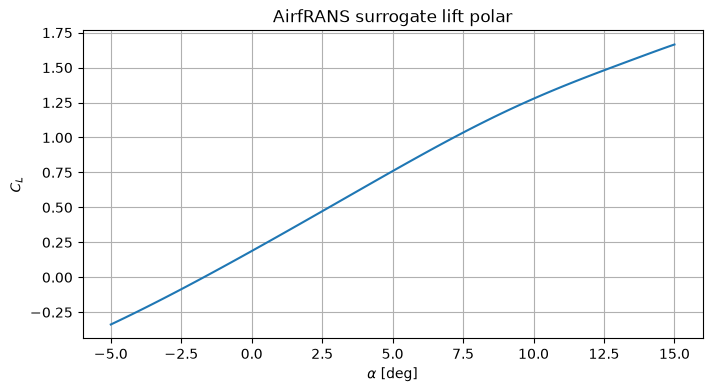

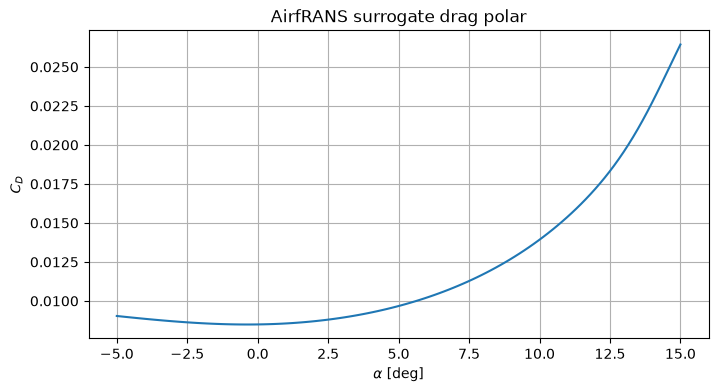

In [6]:
BASE_RE = 4.0e6
BASE_M = 2.0
BASE_P = 4.0
BASE_T = 12.0

alpha_sweep = np.linspace(-5.0, 15.0, 120)

cl_sweep = []
cd_sweep = []

for alpha in alpha_sweep:
    cl_i, cd_i = predict_airfrans_aero(
        BASE_RE,
        alpha,
        BASE_M,
        BASE_P,
        BASE_T,
    )
    cl_sweep.append(cl_i)
    cd_sweep.append(cd_i)

cl_sweep = np.asarray(cl_sweep)
cd_sweep = np.asarray(cd_sweep)

plt.figure(figsize=(8, 4))
plt.plot(alpha_sweep, cl_sweep)
plt.xlabel(r"$\alpha$ [deg]")
plt.ylabel(r"$C_L$")
plt.title("AirfRANS surrogate lift polar")
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(alpha_sweep, cd_sweep)
plt.xlabel(r"$\alpha$ [deg]")
plt.ylabel(r"$C_D$")
plt.title("AirfRANS surrogate drag polar")
plt.grid(True)
plt.show()

## 7. The modelling problem: AirfRANS has no flap input

The environment in Stage 2 used flap deflection as the control action,

$$
a_t \longrightarrow \delta_f.
$$

However, the surrogate trained in Stage 3 has only five inputs:

$$
(Re,\alpha,m,p,t).
$$

There is **no flap-deflection input**.

Therefore we cannot claim that the surrogate directly predicts the aerodynamics of a deflected flap.

For this notebook we retain the equivalent-angle approximation already used in Stage 2:

$$
\alpha_{\mathrm{eq}}
=
\alpha_0
+
\alpha_g
+
\eta_f\delta_f,
$$

where

- $\alpha_0$ is the baseline angle of attack,
- $\alpha_g$ is the gust-induced angle,
- $\eta_f$ is an empirical flap-effectiveness parameter.

The surrogate is then evaluated at

$$
C_{L,\mathrm{qs}},C_D
=
f_{\mathrm{AirfRANS}}
(Re,\alpha_{\mathrm{eq}},m,p,t).
$$

This is a **hybrid approximation**, not a CFD simulation of a moving flap.

## 8. One-minus-cosine gust

We reuse the disturbance from Stage 2.

In [7]:
def one_minus_cosine_gust(t, t0, duration, amplitude):
    if t < t0 or t > t0 + duration:
        return 0.0

    xi = (t - t0) / duration
    return 0.5 * amplitude * (1.0 - np.cos(2.0 * np.pi * xi))

## 9. CFD-informed Gymnasium environment

The observation remains

$$
s_t =
\begin{bmatrix}
C_L &
C_{L,\mathrm{target}} &
\alpha_g &
\delta_f
\end{bmatrix},
$$

after scaling.

The action is continuous:

$$
a_t\in[-1,1],
$$

and maps to a flap command

$$
\delta_{f,\mathrm{cmd}}
=
a_t\,\delta_{f,\max}.
$$

We retain two first-order dynamic models.

### Flap dynamics

$$
\tau_f\dot\delta_f
=
\delta_{f,\mathrm{cmd}}-\delta_f.
$$

### Lift dynamics

AirfRANS supplies a **steady** prediction. We therefore retain

$$
\tau_L\dot C_L
=
C_{L,\mathrm{qs}}-C_L.
$$

The environment is thus not unsteady CFD. It is a steady CFD surrogate embedded in a low-order dynamic model.

In [8]:
class AirfoilSurrogateGymEnv(gym.Env):
    metadata = {"render_modes": []}

    def __init__(
        self,
        dt=0.05,
        horizon=120,
        U_inf=30.0,
        alpha0_deg=5.0,
        cl_target=None,
        max_flap_deg=20.0,
        flap_effectiveness=0.55,
        tau_lift=0.18,
        tau_flap=0.10,
        reynolds=4.0e6,
        naca_m=2.0,
        naca_p=4.0,
        naca_t=12.0,
        random_gust=True,
        gust_amplitude_range=(-3.0, 3.0),
        gust_duration_range=(0.8, 1.8),
        gust_start_range=(1.0, 3.0),
        effort_weight=0.015,
        smoothness_weight=0.020,
        drag_weight=0.020,
    ):
        super().__init__()

        self.dt = dt
        self.horizon = horizon
        self.U_inf = U_inf
        self.alpha0_deg = alpha0_deg
        self.max_flap_deg = max_flap_deg
        self.flap_effectiveness = flap_effectiveness
        self.tau_lift = tau_lift
        self.tau_flap = tau_flap

        self.reynolds = reynolds
        self.naca_m = naca_m
        self.naca_p = naca_p
        self.naca_t = naca_t

        self.random_gust = random_gust
        self.gust_amplitude_range = gust_amplitude_range
        self.gust_duration_range = gust_duration_range
        self.gust_start_range = gust_start_range

        self.effort_weight = effort_weight
        self.smoothness_weight = smoothness_weight
        self.drag_weight = drag_weight

        # If no target is prescribed, use the zero-gust equilibrium lift.
        cl_equilibrium, _ = predict_airfrans_aero(
            self.reynolds,
            self.alpha0_deg,
            self.naca_m,
            self.naca_p,
            self.naca_t,
        )
        self.cl_target = float(cl_equilibrium if cl_target is None else cl_target)

        self.action_space = spaces.Box(
            low=-1.0,
            high=1.0,
            shape=(1,),
            dtype=np.float32,
        )

        self.observation_space = spaces.Box(
            low=np.array([-2.0, -2.0, -2.0, -1.5], dtype=np.float32),
            high=np.array([ 2.0,  2.0,  2.0,  1.5], dtype=np.float32),
            dtype=np.float32,
        )

        self.reset()

    def _gust_velocity(self, t):
        return one_minus_cosine_gust(
            t,
            self.gust_start,
            self.gust_duration,
            self.gust_amplitude,
        )

    def _gust_angle_deg(self, t):
        w_g = self._gust_velocity(t)
        return np.rad2deg(np.arctan2(w_g, self.U_inf))

    def _equivalent_alpha_deg(self, gust_angle_deg):
        return (
            self.alpha0_deg
            + gust_angle_deg
            + self.flap_effectiveness * self.flap_deg
        )

    def _aero(self, gust_angle_deg):
        alpha_eq_deg = self._equivalent_alpha_deg(gust_angle_deg)

        cl_qs, cd = predict_airfrans_aero(
            self.reynolds,
            alpha_eq_deg,
            self.naca_m,
            self.naca_p,
            self.naca_t,
        )

        return cl_qs, cd, alpha_eq_deg

    def _get_obs(self):
        gust_angle_deg = self._gust_angle_deg(self.t)

        obs = np.array([
            self.cl / 1.5,
            self.cl_target / 1.5,
            gust_angle_deg / 10.0,
            self.flap_deg / self.max_flap_deg,
        ], dtype=np.float32)

        return np.clip(
            obs,
            self.observation_space.low,
            self.observation_space.high,
        )

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)

        self.step_count = 0
        self.t = 0.0
        self.prev_action = 0.0
        self.flap_deg = 0.0

        if self.random_gust:
            self.gust_amplitude = self.np_random.uniform(
                *self.gust_amplitude_range
            )
            self.gust_duration = self.np_random.uniform(
                *self.gust_duration_range
            )
            self.gust_start = self.np_random.uniform(
                *self.gust_start_range
            )
        else:
            self.gust_amplitude = 2.5
            self.gust_duration = 1.3
            self.gust_start = 2.0

        self.cl, self.cd = predict_airfrans_aero(
            self.reynolds,
            self.alpha0_deg,
            self.naca_m,
            self.naca_p,
            self.naca_t,
        )

        return self._get_obs(), {}

    def step(self, action):
        action = np.asarray(action, dtype=np.float32).reshape(-1)
        action_value = float(np.clip(action[0], -1.0, 1.0))

        flap_command_deg = action_value * self.max_flap_deg

        # First-order actuator dynamics.
        self.flap_deg += (
            self.dt / self.tau_flap
        ) * (flap_command_deg - self.flap_deg)

        gust_angle_deg = self._gust_angle_deg(self.t)

        cl_qs, cd, alpha_eq_deg = self._aero(gust_angle_deg)

        # First-order lift dynamics.
        self.cl += (
            self.dt / self.tau_lift
        ) * (cl_qs - self.cl)

        self.cd = cd

        tracking_error = self.cl - self.cl_target
        delta_action = action_value - self.prev_action

        reward = (
            -tracking_error**2
            -self.effort_weight * action_value**2
            -self.smoothness_weight * delta_action**2
            -self.drag_weight * cd
        )

        self.prev_action = action_value
        self.step_count += 1
        self.t = self.step_count * self.dt

        terminated = False
        truncated = self.step_count >= self.horizon

        info = {
            "time": self.t,
            "cl": self.cl,
            "cl_qs": cl_qs,
            "cl_target": self.cl_target,
            "cd": cd,
            "flap_deg": self.flap_deg,
            "flap_command_deg": flap_command_deg,
            "gust_velocity": self._gust_velocity(self.t),
            "gust_angle_deg": self._gust_angle_deg(self.t),
            "alpha_eq_deg": alpha_eq_deg,
            "tracking_error": tracking_error,
        }

        return (
            self._get_obs(),
            float(reward),
            terminated,
            truncated,
            info,
        )

## 10. Check the custom environment

Before training a neural network, always verify that the Gymnasium interface is valid.

In [9]:
test_env = AirfoilSurrogateGymEnv(
    random_gust=True,
)

check_env(test_env, warn=True)

print("Environment check passed.")
print(f"Target CL = {test_env.cl_target:.4f}")

Environment check passed.
Target CL = 0.7595


## 11. Inspect one episode with random actions

This is a basic physical sanity check. We want to confirm that:

- the gust has the expected shape,
- the flap remains within its limits,
- the effective angle changes,
- the surrogate returns finite coefficients,
- the episode terminates correctly.

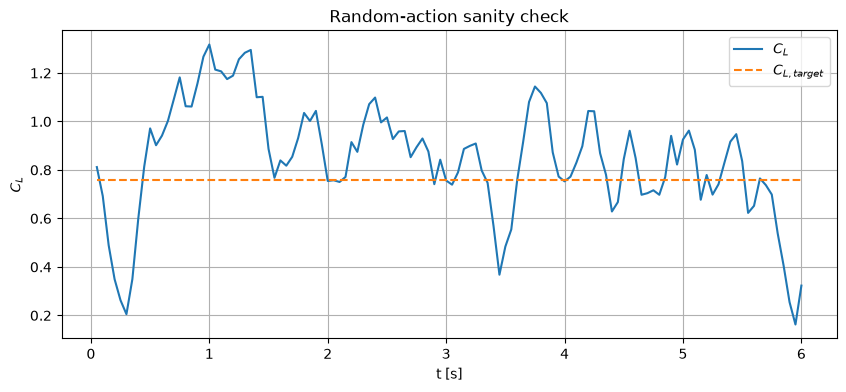

In [10]:
random_env = AirfoilSurrogateGymEnv(
    random_gust=False,
)

obs, _ = random_env.reset(seed=SEED)

random_data = {
    "time": [],
    "cl": [],
    "cl_target": [],
    "cd": [],
    "flap_deg": [],
    "gust_velocity": [],
    "alpha_eq_deg": [],
}

terminated = truncated = False

while not (terminated or truncated):
    action = random_env.action_space.sample()

    obs, reward, terminated, truncated, info = random_env.step(action)

    for key in random_data:
        random_data[key].append(info[key])

for key in random_data:
    random_data[key] = np.asarray(random_data[key])

plt.figure(figsize=(10, 4))
plt.plot(random_data["time"], random_data["cl"], label=r"$C_L$")
plt.plot(
    random_data["time"],
    random_data["cl_target"],
    "--",
    label=r"$C_{L,target}$",
)
plt.xlabel("t [s]")
plt.ylabel(r"$C_L$")
plt.title("Random-action sanity check")
plt.legend()
plt.grid(True)
plt.show()

## 12. Select the DRL algorithm

The action is continuous, so we keep the three algorithms introduced in Stage 2.

Change only:

```python
MODEL_NAME = "SAC"
```

to compare PPO, SAC, and TD3.

In [11]:
MODEL_NAME = "SAC"      # "PPO", "SAC", or "TD3"
TOTAL_TIMESTEPS = 50_000

training_env = Monitor(
    AirfoilSurrogateGymEnv(
        random_gust=True,
    )
)

if MODEL_NAME == "PPO":
    model = PPO(
        policy="MlpPolicy",
        env=training_env,
        learning_rate=3e-4,
        n_steps=1024,
        batch_size=64,
        gamma=0.99,
        verbose=1,
        seed=SEED,
    )

elif MODEL_NAME == "SAC":
    model = SAC(
        policy="MlpPolicy",
        env=training_env,
        learning_rate=3e-4,
        buffer_size=100_000,
        batch_size=256,
        gamma=0.99,
        verbose=1,
        seed=SEED,
    )

elif MODEL_NAME == "TD3":
    n_actions = training_env.action_space.shape[-1]

    action_noise = NormalActionNoise(
        mean=np.zeros(n_actions),
        sigma=0.10 * np.ones(n_actions),
    )

    model = TD3(
        policy="MlpPolicy",
        env=training_env,
        learning_rate=1e-3,
        buffer_size=100_000,
        batch_size=256,
        gamma=0.99,
        action_noise=action_noise,
        verbose=1,
        seed=SEED,
    )

else:
    raise ValueError(
        "MODEL_NAME must be 'PPO', 'SAC', or 'TD3'"
    )

print(f"Selected model: {MODEL_NAME}")

Using cpu device
Wrapping the env in a DummyVecEnv.


Selected model: SAC


## 13. Train the CFD-informed controller

The agent now interacts with the surrogate thousands of times.

A direct RANS solver would make this training loop impractical for a classroom exercise. The surrogate makes the environment inexpensive enough to use with DRL.

## Animation step 1 — record snapshots while the agent learns

The pattern: **train once and save snapshots**. Every `SNAPSHOT_EVERY` steps the current policy flies the fixed evaluation gust (deterministic actions); after training the agent is saved to `trained_models/`.

In [12]:
# ================================================================
# ANIMATION STEP 1 — SNAPSHOT CALLBACK
# Every SNAPSHOT_EVERY steps the current policy flies the fixed evaluation gust
# (random_gust=False) once, deterministically; the episode is stored.
# ================================================================
import pickle
from pathlib import Path
from stable_baselines3.common.callbacks import BaseCallback

ANIM_DIR = Path("../animations"); ANIM_DIR.mkdir(exist_ok=True)
MODEL_DIR = Path("../models/04_airfoil_gust_control_cfd_surrogate"); MODEL_DIR.mkdir(exist_ok=True)
SNAPSHOT_EVERY = 1_000
TRACE_KEYS = ["time", "cl", "cl_target", "cd", "flap_deg", "gust_velocity", "gust_angle_deg", "alpha_eq_deg"]


def fixed_gust_rollout(policy, env):
    obs, _ = env.reset(seed=0)
    out = {k: [] for k in TRACE_KEYS + ["reward"]}
    done = False
    while not done:
        action, _ = policy.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated
        for k in TRACE_KEYS:
            out[k].append(info[k])
        out["reward"].append(reward)
    return {k: np.asarray(v) for k, v in out.items()}


class AirfoilSnapshotCallback(BaseCallback):
    def __init__(self, monitor, every, env_factory):
        super().__init__()
        self.monitor, self.every, self.env_factory = monitor, every, env_factory
        self.snapshots = []

    def _take(self):
        trace = fixed_gust_rollout(self.model, self.env_factory())
        self.snapshots.append({
            "timestep": int(self.num_timesteps), "trace": trace,
            "episode_rewards": list(self.monitor.get_episode_rewards()),
            "episode_lengths": list(self.monitor.get_episode_lengths()),
        })

    def _on_training_start(self):
        self._take()

    def _on_step(self):
        if self.num_timesteps % self.every == 0:
            self._take()
        return True


snapshot_callback = AirfoilSnapshotCallback(training_env, SNAPSHOT_EVERY, lambda: AirfoilSurrogateGymEnv(random_gust=False))
print(f"Snapshot every {SNAPSHOT_EVERY:,} steps -> {TOTAL_TIMESTEPS // SNAPSHOT_EVERY + 1} frames")

Snapshot every 1,000 steps -> 51 frames


In [13]:
model.learn(total_timesteps=TOTAL_TIMESTEPS, callback=snapshot_callback)  # callback added for the animation

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 120      |
|    ep_rew_mean     | -9.04    |
| time/              |          |
|    episodes        | 4        |
|    fps             | 197      |
|    time_elapsed    | 2        |
|    total_timesteps | 480      |
| train/             |          |
|    actor_loss      | -1.96    |
|    critic_loss     | 0.0114   |
|    ent_coef        | 0.893    |
|    ent_coef_loss   | -0.19    |
|    learning_rate   | 0.0003   |
|    n_updates       | 379      |
---------------------------------


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 120      |
|    ep_rew_mean     | -8.33    |
| time/              |          |
|    episodes        | 8        |
|    fps             | 179      |
|    time_elapsed    | 5        |
|    total_timesteps | 960      |
| train/             |          |
|    actor_loss      | -2.86    |
|    critic_loss     | 0.00857  |
|    ent_coef        | 0.773    |
|    ent_coef_loss   | -0.433   |
|    learning_rate   | 0.0003   |
|    n_updates       | 859      |
---------------------------------


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 120      |
|    ep_rew_mean     | -7.95    |
| time/              |          |
|    episodes        | 12       |
|    fps             | 173      |
|    time_elapsed    | 8        |
|    total_timesteps | 1440     |
| train/             |          |
|    actor_loss      | -3.59    |
|    critic_loss     | 0.00803  |
|    ent_coef        | 0.67     |
|    ent_coef_loss   | -0.675   |
|    learning_rate   | 0.0003   |
|    n_updates       | 1339     |
---------------------------------


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 120      |
|    ep_rew_mean     | -7.58    |
| time/              |          |
|    episodes        | 16       |
|    fps             | 171      |
|    time_elapsed    | 11       |
|    total_timesteps | 1920     |
| train/             |          |
|    actor_loss      | -4.24    |
|    critic_loss     | 0.00965  |
|    ent_coef        | 0.58     |
|    ent_coef_loss   | -0.9     |
|    learning_rate   | 0.0003   |
|    n_updates       | 1819     |
---------------------------------


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 120      |
|    ep_rew_mean     | -7.45    |
| time/              |          |
|    episodes        | 20       |
|    fps             | 169      |
|    time_elapsed    | 14       |
|    total_timesteps | 2400     |
| train/             |          |
|    actor_loss      | -4.75    |
|    critic_loss     | 0.00596  |
|    ent_coef        | 0.503    |
|    ent_coef_loss   | -1.13    |
|    learning_rate   | 0.0003   |
|    n_updates       | 2299     |
---------------------------------


...

---------------------------------
| rollout/           |          |
|    ep_len_mean     | 120      |
|    ep_rew_mean     | -0.566   |
| time/              |          |
|    episodes        | 400      |
|    fps             | 163      |
|    time_elapsed    | 293      |
|    total_timesteps | 48000    |
| train/             |          |
|    actor_loss      | -0.34    |
|    critic_loss     | 0.00154  |
|    ent_coef        | 0.00291  |
|    ent_coef_loss   | -0.0434  |
|    learning_rate   | 0.0003   |
|    n_updates       | 47899    |
---------------------------------


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 120      |
|    ep_rew_mean     | -0.56    |
| time/              |          |
|    episodes        | 404      |
|    fps             | 163      |
|    time_elapsed    | 296      |
|    total_timesteps | 48480    |
| train/             |          |
|    actor_loss      | -0.342   |
|    critic_loss     | 0.00106  |
|    ent_coef        | 0.00289  |
|    ent_coef_loss   | -0.179   |
|    learning_rate   | 0.0003   |
|    n_updates       | 48379    |
---------------------------------


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 120      |
|    ep_rew_mean     | -0.549   |
| time/              |          |
|    episodes        | 408      |
|    fps             | 163      |
|    time_elapsed    | 299      |
|    total_timesteps | 48960    |
| train/             |          |
|    actor_loss      | -0.322   |
|    critic_loss     | 0.00116  |
|    ent_coef        | 0.00299  |
|    ent_coef_loss   | -0.469   |
|    learning_rate   | 0.0003   |
|    n_updates       | 48859    |
---------------------------------


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 120      |
|    ep_rew_mean     | -0.55    |
| time/              |          |
|    episodes        | 412      |
|    fps             | 163      |
|    time_elapsed    | 302      |
|    total_timesteps | 49440    |
| train/             |          |
|    actor_loss      | -0.305   |
|    critic_loss     | 0.00102  |
|    ent_coef        | 0.0029   |
|    ent_coef_loss   | -0.143   |
|    learning_rate   | 0.0003   |
|    n_updates       | 49339    |
---------------------------------


---------------------------------
| rollout/           |          |
|    ep_len_mean     | 120      |
|    ep_rew_mean     | -0.54    |
| time/              |          |
|    episodes        | 416      |
|    fps             | 163      |
|    time_elapsed    | 305      |
|    total_timesteps | 49920    |
| train/             |          |
|    actor_loss      | -0.277   |
|    critic_loss     | 0.000888 |
|    ent_coef        | 0.00288  |
|    ent_coef_loss   | 0.513    |
|    learning_rate   | 0.0003   |
|    n_updates       | 49819    |
---------------------------------


In [14]:
# ================================================================
# ANIMATION STEP 1b + MODEL SAVE
# ================================================================
FINAL_MODEL_PATH = MODEL_DIR / f"airfoil_surrogate_{MODEL_NAME.lower()}_final"
model.save(FINAL_MODEL_PATH)
print("Saved trained agent:", str(FINAL_MODEL_PATH) + ".zip")

SNAPSHOT_FILE = ANIM_DIR / "04_airfoil_surrogate_training_snapshots.pkl"
pickle.dump({"snapshots": snapshot_callback.snapshots, "algo": MODEL_NAME,
             "total_timesteps": TOTAL_TIMESTEPS}, open(SNAPSHOT_FILE, "wb"))
print(f"{len(snapshot_callback.snapshots)} snapshots saved to {SNAPSHOT_FILE}")

Saved trained agent: ../models/04_airfoil_gust_control_cfd_surrogate/airfoil_surrogate_sac_final.zip
51 snapshots saved to ../animations/04_airfoil_surrogate_training_snapshots.pkl


## 14. Episode runner

In [15]:
def run_episode(env, policy, seed=0):
    obs, _ = env.reset(seed=seed)

    data = {
        "time": [],
        "cl": [],
        "cl_qs": [],
        "cl_target": [],
        "cd": [],
        "flap_deg": [],
        "flap_command_deg": [],
        "gust_velocity": [],
        "gust_angle_deg": [],
        "alpha_eq_deg": [],
        "reward": [],
    }

    terminated = truncated = False

    while not (terminated or truncated):
        action, _ = policy.predict(obs, deterministic=True)

        obs, reward, terminated, truncated, info = env.step(action)

        for key in data:
            if key == "reward":
                data[key].append(reward)
            else:
                data[key].append(info[key])

    return {
        key: np.asarray(value)
        for key, value in data.items()
    }


class ZeroPolicy:
    def predict(self, obs, deterministic=True):
        return np.array([0.0], dtype=np.float32), None

## 15. Evaluate on a fixed gust

Training uses randomized disturbances. Evaluation should use an identical prescribed gust for both the controlled and uncontrolled cases.

In [16]:
controlled_env = AirfoilSurrogateGymEnv(
    random_gust=False,
)

uncontrolled_env = AirfoilSurrogateGymEnv(
    random_gust=False,
)

controlled = run_episode(
    controlled_env,
    policy=model,
    seed=123,
)

uncontrolled = run_episode(
    uncontrolled_env,
    policy=ZeroPolicy(),
    seed=123,
)

## 16. Visual comparison

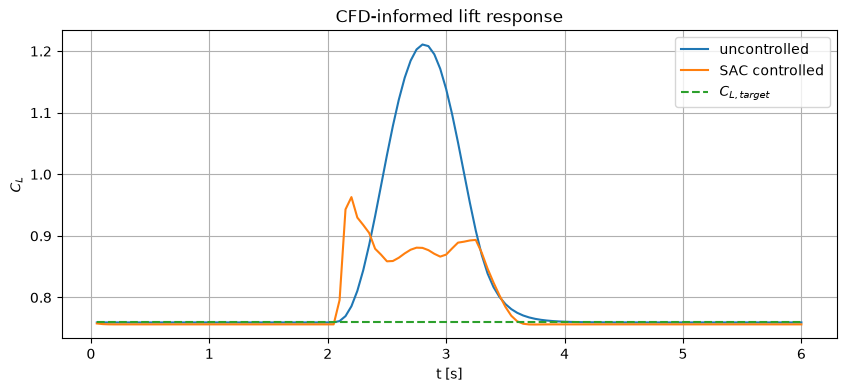

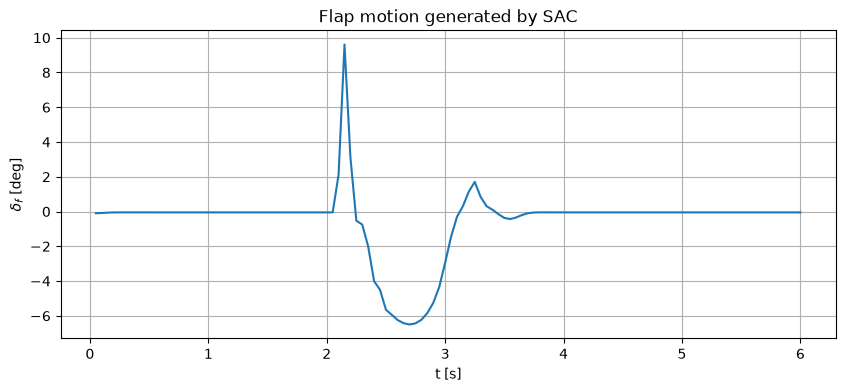

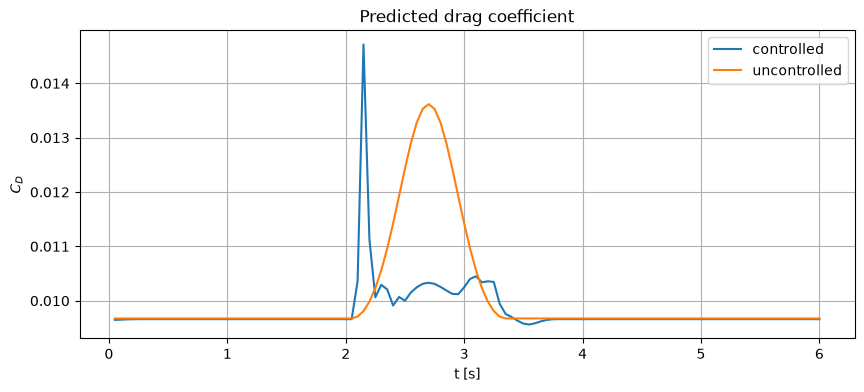

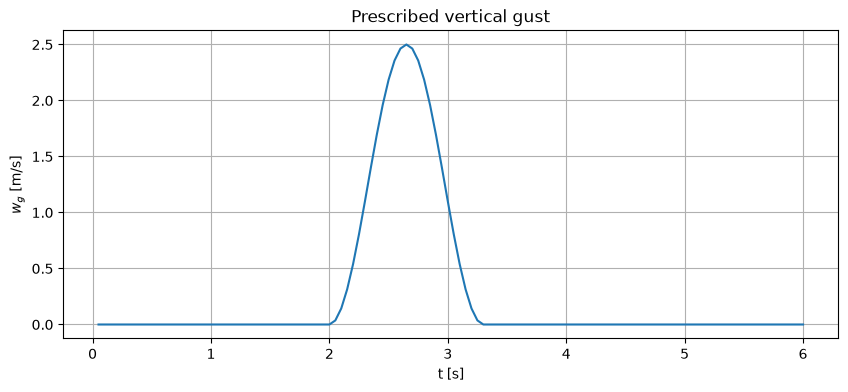

In [17]:
plt.figure(figsize=(10, 4))
plt.plot(
    uncontrolled["time"],
    uncontrolled["cl"],
    label="uncontrolled",
)
plt.plot(
    controlled["time"],
    controlled["cl"],
    label=f"{MODEL_NAME} controlled",
)
plt.plot(
    controlled["time"],
    controlled["cl_target"],
    "--",
    label=r"$C_{L,target}$",
)
plt.xlabel("t [s]")
plt.ylabel(r"$C_L$")
plt.title("CFD-informed lift response")
plt.legend()
plt.grid(True)
plt.show()


plt.figure(figsize=(10, 4))
plt.plot(
    controlled["time"],
    controlled["flap_deg"],
)
plt.xlabel("t [s]")
plt.ylabel(r"$\delta_f$ [deg]")
plt.title(f"Flap motion generated by {MODEL_NAME}")
plt.grid(True)
plt.show()


plt.figure(figsize=(10, 4))
plt.plot(
    controlled["time"],
    controlled["cd"],
    label="controlled",
)
plt.plot(
    uncontrolled["time"],
    uncontrolled["cd"],
    label="uncontrolled",
)
plt.xlabel("t [s]")
plt.ylabel(r"$C_D$")
plt.title("Predicted drag coefficient")
plt.legend()
plt.grid(True)
plt.show()


plt.figure(figsize=(10, 4))
plt.plot(
    controlled["time"],
    controlled["gust_velocity"],
)
plt.xlabel("t [s]")
plt.ylabel(r"$w_g$ [m/s]")
plt.title("Prescribed vertical gust")
plt.grid(True)
plt.show()

## 17. Quantitative metrics

We use the same basic performance measures as in Stage 2:

$$
\mathrm{RMSE}(C_L)
=
\sqrt{
\frac{1}{N}
\sum_{i=1}^{N}
(C_{L,i}-C_{L,\mathrm{target}})^2
},
$$

together with

- mean absolute flap deflection,
- maximum flap deflection,
- mean predicted drag,
- total episode reward.

In [18]:
def episode_metrics(data):
    error = data["cl"] - data["cl_target"]

    return {
        "CL_RMSE": np.sqrt(np.mean(error**2)),
        "mean_abs_flap_deg": np.mean(np.abs(data["flap_deg"])),
        "max_abs_flap_deg": np.max(np.abs(data["flap_deg"])),
        "mean_CD": np.mean(data["cd"]),
        "episode_return": np.sum(data["reward"]),
    }


metrics_uncontrolled = episode_metrics(uncontrolled)
metrics_controlled = episode_metrics(controlled)

comparison = pd.DataFrame(
    [
        metrics_uncontrolled,
        metrics_controlled,
    ],
    index=[
        "Uncontrolled",
        f"{MODEL_NAME} controlled",
    ],
)

comparison

,CL_RMSE,mean_abs_flap_deg,max_abs_flap_deg,mean_CD,episode_return
Uncontrolled,0.135357,0.000000,0.000000,0.010051,-2.222713
SAC controlled,0.059620,0.839439,9.610354,0.009820,-0.511805


## 18. Test the learned policy on unseen gusts

A controller is more interesting if it can regulate disturbances that were not identical to the one used for demonstration.

In [19]:
def evaluate_on_gust(
    policy,
    amplitude,
    duration,
    start=2.0,
    seed=0,
    **env_kwargs,
):
    env = AirfoilSurrogateGymEnv(
        random_gust=False,
        **env_kwargs,
    )

    obs, _ = env.reset(seed=seed)

    env.gust_amplitude = amplitude
    env.gust_duration = duration
    env.gust_start = start

    data = {
        "time": [],
        "cl": [],
        "cl_qs": [],
        "cl_target": [],
        "cd": [],
        "flap_deg": [],
        "flap_command_deg": [],
        "gust_velocity": [],
        "gust_angle_deg": [],
        "alpha_eq_deg": [],
        "reward": [],
    }

    terminated = truncated = False

    while not (terminated or truncated):
        action, _ = policy.predict(obs, deterministic=True)

        obs, reward, terminated, truncated, info = env.step(action)

        for key in data:
            if key == "reward":
                data[key].append(reward)
            else:
                data[key].append(info[key])

    return {
        key: np.asarray(value)
        for key, value in data.items()
    }


test_cases = [
    (-3.5, 1.0),
    (-2.0, 1.7),
    ( 2.0, 1.1),
    ( 3.5, 1.6),
]

rows = []

for amplitude, duration in test_cases:
    result = evaluate_on_gust(
        model,
        amplitude=amplitude,
        duration=duration,
        start=2.0,
    )

    metrics = episode_metrics(result)

    rows.append({
        "W0 [m/s]": amplitude,
        "Tg [s]": duration,
        **metrics,
    })

pd.DataFrame(rows)

,W0 [m/s],Tg [s],CL_RMSE,mean_abs_flap_deg,max_abs_flap_deg,mean_CD,episode_return
0,-3.5,1.0,0.040510,1.088236,10.680001,0.009688,-0.274878
1,-2.0,1.7,0.037219,1.267361,6.265274,0.009735,-0.220818
2,2.0,1.1,0.055807,0.601537,9.653209,0.009801,-0.449342
3,3.5,1.6,0.078000,1.311922,9.471893,0.009885,-0.835862


# Part B — What changed relative to Stage 2?

## 19. Reconstruct the low-order aerodynamic model

To make the comparison explicit, we reproduce the original analytical approximation:

$$
C_{L,\mathrm{qs}}=2\pi\alpha_{\mathrm{eff}},
$$

with

$$
C_D=C_{D0}+kC_L^2+k_f\delta_f^2.
$$

This is not intended as a competing high-fidelity model. It is a baseline that lets us isolate the consequence of changing the aerodynamic environment.

In [20]:
def low_order_lift(alpha_rad):
    return 2.0 * np.pi * alpha_rad


def low_order_aero(
    alpha_eff_deg,
    cl_current,
    flap_deg,
    cd0=0.012,
    induced_drag_factor=0.025,
    flap_drag_factor=0.08,
):
    alpha_eff_rad = np.deg2rad(alpha_eff_deg)
    cl_qs = low_order_lift(alpha_eff_rad)

    flap_rad = np.deg2rad(flap_deg)

    cd = (
        cd0
        + induced_drag_factor * cl_current**2
        + flap_drag_factor * flap_rad**2
    )

    return float(cl_qs), float(cd)

## 20. Compare the static aerodynamic laws directly

Before comparing controllers, compare the models themselves.

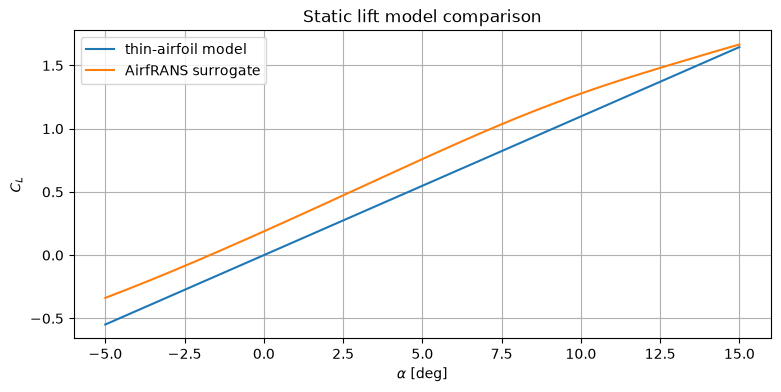

In [21]:
alpha_compare = np.linspace(-5.0, 15.0, 150)

cl_low = 2.0 * np.pi * np.deg2rad(alpha_compare)

cl_cfd = []
cd_cfd = []

for alpha in alpha_compare:
    cl_i, cd_i = predict_airfrans_aero(
        BASE_RE,
        alpha,
        BASE_M,
        BASE_P,
        BASE_T,
    )
    cl_cfd.append(cl_i)
    cd_cfd.append(cd_i)

cl_cfd = np.asarray(cl_cfd)
cd_cfd = np.asarray(cd_cfd)

plt.figure(figsize=(9, 4))
plt.plot(
    alpha_compare,
    cl_low,
    label="thin-airfoil model",
)
plt.plot(
    alpha_compare,
    cl_cfd,
    label="AirfRANS surrogate",
)
plt.xlabel(r"$\alpha$ [deg]")
plt.ylabel(r"$C_L$")
plt.title("Static lift model comparison")
plt.legend()
plt.grid(True)
plt.show()

## 21. Why the controller may change

In reinforcement learning, the environment determines the transition and reward experienced by the agent.

Replacing

$$
C_L=2\pi\alpha
$$

by

$$
C_L=f_{\mathrm{CFD}}(Re,\alpha,m,p,t)
$$

changes the map

$$
(s_t,a_t)
\longrightarrow
(s_{t+1},r_t).
$$

Therefore, even if

- the observation is unchanged,
- the action is unchanged,
- the reward weights are unchanged,
- the DRL algorithm is unchanged,

the **optimal policy need not be the same**.

This is the central conceptual point of Stage 4.

## 22. Optional experiment — train a low-order baseline controller

For a fully controlled comparison, train a second agent using the original Stage 2 environment and evaluate both controllers on matched gusts.

A useful experiment is:

1. keep the same algorithm,
2. keep the same random seed,
3. keep the same number of training steps,
4. change only the aerodynamic model,
5. compare lift regulation, flap activity, and drag.

This isolates the influence of model fidelity on the learned policy.

# Part C — Validity and generalization

## 23. Stay inside the surrogate domain

A neural-network surrogate is generally much safer in interpolation than in extrapolation.

During an episode, the equivalent angle

$$
\alpha_{\mathrm{eq}}
=
\alpha_0+\alpha_g+\eta_f\delta_f
$$

may leave the range represented in the AirfRANS training data.

That is a serious issue because the DRL agent can deliberately search unusual regions of the state-action space.

We therefore monitor the range of $\alpha_{\mathrm{eq}}$.

In [22]:
alpha_min_episode = np.min(controlled["alpha_eq_deg"])
alpha_max_episode = np.max(controlled["alpha_eq_deg"])

print(
    "Equivalent-angle range during controlled episode:"
)
print(
    f"{alpha_min_episode:.2f} deg to "
    f"{alpha_max_episode:.2f} deg"
)

Equivalent-angle range during controlled episode:
4.76 deg to 10.56 deg


# 23b. Animation — the controller learning to reject the gust

Following the same pattern (train and save snapshots → preview the final frame → render), the dashboard shows, for every snapshot of the policy during training, one flight through the fixed evaluation gust:

- **Top-left — lift response**: $C_L(t)$ of the current policy, the uncontrolled response and the target.
- **Top-right — training curve**: the return of every training episode logged so far, with a moving average; the dotted line marks the snapshot.
- **Bottom-left — flap deflection** $\delta_f(t)$ chosen by the current policy.
- **Bottom-right — angles**: the gust-induced angle and the resulting equivalent angle $\alpha_{\mathrm{eq}}$ seen by the surrogate; the shaded band is the angle range covered by the CFD training data, so the animation also shows whether the policy keeps the surrogate inside its data.

A second animation then shows the **airfoil itself** flying through the gust, uncontrolled and controlled.

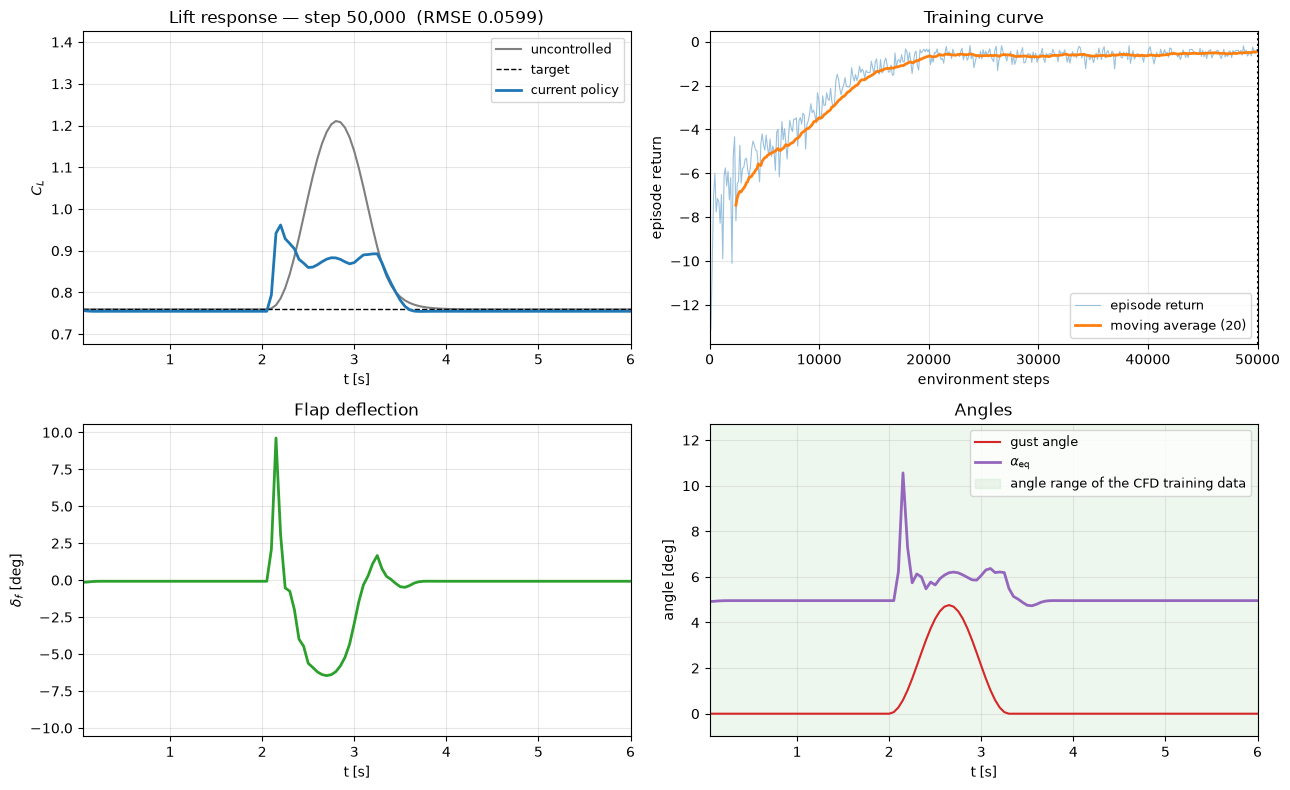

In [23]:
# ================================================================
# ANIMATION CELL 2 — PREVIEW THE FINAL FRAME
# ================================================================
import pickle
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display

anim_data = pickle.load(open(ANIM_DIR / "04_airfoil_surrogate_training_snapshots.pkl", "rb"))
snaps = anim_data["snapshots"]
unc = uncontrolled
final_rewards = np.asarray(snaps[-1]["episode_rewards"])
cl_all = np.concatenate([s["trace"]["cl"] for s in snaps] + [unc["cl"]])
flap_all = np.concatenate([s["trace"]["flap_deg"] for s in snaps])
alpha_all = np.concatenate([s["trace"]["alpha_eq_deg"] for s in snaps] + [s["trace"]["gust_angle_deg"] for s in snaps])


def build_airfoil_dashboard():
    fig, axes = plt.subplots(2, 2, figsize=(13, 8))
    ax_cl, ax_r, ax_f, ax_a = axes[0, 0], axes[0, 1], axes[1, 0], axes[1, 1]
    t = snaps[0]["trace"]["time"]

    ax_cl.plot(unc["time"], unc["cl"], color="tab:gray", lw=1.5, label="uncontrolled")
    ax_cl.plot(t, snaps[0]["trace"]["cl_target"], "k--", lw=1, label="target")
    cl_line, = ax_cl.plot([], [], color="tab:blue", lw=2, label="current policy")
    ax_cl.set_xlim(t[0], t[-1]); ax_cl.set_ylim(cl_all.min() - 0.05, cl_all.max() + 0.05)
    ax_cl.set_xlabel("t [s]"); ax_cl.set_ylabel(r"$C_L$"); ax_cl.grid(True, alpha=0.3); ax_cl.legend(fontsize=9)
    title_cl = ax_cl.set_title("")

    ax_r.set_xlim(0, anim_data["total_timesteps"])
    pad = 0.05 * (final_rewards.max() - final_rewards.min() + 1e-9)
    ax_r.set_ylim(final_rewards.min() - pad, final_rewards.max() + pad)
    ax_r.set_xlabel("environment steps"); ax_r.set_ylabel("episode return"); ax_r.set_title("Training curve")
    ax_r.grid(True, alpha=0.3)
    rew_line, = ax_r.plot([], [], lw=0.8, alpha=0.45, label="episode return")
    avg_line, = ax_r.plot([], [], lw=2.0, label="moving average (20)")
    vline = ax_r.axvline(0, color="k", ls=":")
    ax_r.legend(loc="lower right", fontsize=9)

    flap_line, = ax_f.plot([], [], color="tab:green", lw=2)
    lim = max(1.0, np.abs(flap_all).max() * 1.1)
    ax_f.set_xlim(t[0], t[-1]); ax_f.set_ylim(-lim, lim)
    ax_f.set_xlabel("t [s]"); ax_f.set_ylabel(r"$\delta_f$ [deg]"); ax_f.set_title("Flap deflection")
    ax_f.grid(True, alpha=0.3)

    gust_line, = ax_a.plot([], [], color="tab:red", lw=1.5, label="gust angle")
    alpha_line, = ax_a.plot([], [], color="tab:purple", lw=2, label="$\\alpha_{\\mathrm{eq}}$")
    _trust = pd.read_csv("../data/airfrans_4digit_coefficients.csv").query("split == 'train'").alpha_deg
    ax_a.axhspan(_trust.min(), _trust.max(), color="tab:green", alpha=0.08, label="angle range of the CFD training data")
    ax_a.set_xlim(t[0], t[-1]); ax_a.set_ylim(alpha_all.min() - 1, alpha_all.max() + 1)
    ax_a.set_xlabel("t [s]"); ax_a.set_ylabel("angle [deg]"); ax_a.set_title("Angles")
    ax_a.grid(True, alpha=0.3); ax_a.legend(fontsize=9, loc="upper right")

    def update(k):
        s = snaps[k]; tr = s["trace"]
        cl_line.set_data(tr["time"], tr["cl"])
        rmse = np.sqrt(np.mean((tr["cl"] - tr["cl_target"])**2))
        title_cl.set_text(f"Lift response — step {s['timestep']:,}  (RMSE {rmse:.4f})")
        rewards = np.asarray(s["episode_rewards"])
        if len(rewards):
            steps = np.cumsum(s["episode_lengths"])
            rew_line.set_data(steps, rewards)
            w = min(20, len(rewards))
            avg = np.convolve(rewards, np.ones(w) / w, mode="valid")
            avg_line.set_data(steps[len(steps) - len(avg):], avg)
        vline.set_xdata([s["timestep"], s["timestep"]])
        flap_line.set_data(tr["time"], tr["flap_deg"])
        gust_line.set_data(tr["time"], tr["gust_angle_deg"])
        alpha_line.set_data(tr["time"], tr["alpha_eq_deg"])
        return [cl_line, rew_line, avg_line, vline, flap_line, gust_line, alpha_line]

    fig.tight_layout()
    return fig, update


fig, update = build_airfoil_dashboard()
update(len(snaps) - 1)
fig.savefig(ANIM_DIR / "04_airfoil_surrogate_training_dashboard_final_frame.png", dpi=120)
plt.show()

In [24]:
# ================================================================
# ANIMATION CELL 3 — RENDER THE TRAINING ANIMATION
# ================================================================
N_HOLD = 12
frames = list(range(len(snaps))) + [len(snaps) - 1] * N_HOLD
print("Total frames:", len(frames))
fig, update = build_airfoil_dashboard()
anim = FuncAnimation(fig, lambda i: update(frames[i]), frames=len(frames), interval=150, blit=False)
anim.save(ANIM_DIR / "04_airfoil_surrogate_training_dashboard.mp4", writer="ffmpeg", fps=7, dpi=100)
plt.close(fig)
print("Saved:", ANIM_DIR / "04_airfoil_surrogate_training_dashboard.mp4")
HTML(anim.to_html5_video())

Total frames: 63


Saved: ../animations/04_airfoil_surrogate_training_dashboard.mp4


### Animation 2 — the airfoil flying through the gust

Left: the airfoil at its geometric angle $\alpha_0$, drawn as a NACA 2412 (the baseline geometry of the surrogate) section with a plain flap hinged at 75 % chord. Freestream arrows tilt with the gust angle, the solid arrow is the current lift coefficient and the dashed arrow the target. Top row uncontrolled, bottom row controlled by the trained policy. Right: the lift histories with a moving marker. The drawing is a visual aid; the dynamics are exactly those of the environment.

In [25]:
# ================================================================
# ANIMATION 2 — AIRFOIL FLIGHT THROUGH THE GUST
# ================================================================
def naca4_outline(m=0.0, p=0.0, t=12.0, n=80):
    """Closed outline of a NACA four-digit section (m, p in digits as in the dataset, t in % chord)."""
    m, p, t = m / 100.0, p / 10.0, t / 100.0
    beta = np.linspace(0.0, np.pi, n); xc = 0.5 * (1 - np.cos(beta))
    yt = 5 * t * (0.2969 * np.sqrt(xc) - 0.1260 * xc - 0.3516 * xc**2 + 0.2843 * xc**3 - 0.1015 * xc**4)
    if m > 0 and p > 0:
        yc = np.where(xc < p, m / p**2 * (2 * p * xc - xc**2), m / (1 - p)**2 * ((1 - 2 * p) + 2 * p * xc - xc**2))
    else:
        yc = np.zeros_like(xc)
    xu, yu, xl, yl = xc, yc + yt, xc, yc - yt
    return np.concatenate([xu[::-1], xl[1:]]), np.concatenate([yu[::-1], yl[1:]])


def rotate(xs, ys, angle_deg, cx=0.0, cy=0.0):
    a = np.deg2rad(angle_deg)
    xr, yr = xs - cx, ys - cy
    return cx + xr * np.cos(a) - yr * np.sin(a), cy + xr * np.sin(a) + yr * np.cos(a)


AF_X, AF_Y = naca4_outline(2.0, 4.0, 12.0)
HINGE = 0.75


def airfoil_shape(alpha0_deg, flap_deg):
    xs, ys = AF_X.copy(), AF_Y.copy()
    aft = xs > HINGE
    xs[aft], ys[aft] = rotate(xs[aft], ys[aft], -flap_deg, HINGE, 0.0)   # flap down for positive deflection
    return rotate(xs - 0.25, ys, -alpha0_deg)                              # nose up by alpha0 about c/4


ctl = fixed_gust_rollout(model, AirfoilSurrogateGymEnv(random_gust=False))
runs = {"uncontrolled": unc, f"{MODEL_NAME} controlled": ctl}
alpha0 = 5.0

fig = plt.figure(figsize=(13, 6.5))
gs = fig.add_gridspec(2, 2, width_ratios=[1.25, 1])
art = {}
for row, (name, tr) in enumerate(runs.items()):
    ax = fig.add_subplot(gs[row, 0]); ax.set_xlim(-0.9, 1.25); ax.set_ylim(-0.55, 0.85)
    ax.set_aspect("equal"); ax.axis("off"); ax.set_title(name, fontsize=11)
    xs, ys = airfoil_shape(alpha0, 0.0)
    poly = ax.fill(xs, ys, color="#4c72b0" if row else "#8c8c8c", alpha=0.85)[0]
    arrows = [ax.annotate("", xy=(-0.45, y0), xytext=(-0.85, y0),
                          arrowprops=dict(arrowstyle="->", color="tab:red", lw=1.3)) for y0 in (-0.35, -0.1, 0.15, 0.4)]
    lift = ax.annotate("", xy=(0.0, 0.0), xytext=(0.0, 0.0), arrowprops=dict(arrowstyle="-|>", color="k", lw=2.5))
    target = ax.annotate("", xy=(0.12, 0.0), xytext=(0.12, 0.0),
                         arrowprops=dict(arrowstyle="-|>", color="tab:orange", lw=1.5, ls="--"))
    text = ax.text(0.55, 0.72, "", fontsize=9, family="monospace")
    art[name] = (poly, arrows, lift, target, text, tr)

ax_tr = fig.add_subplot(gs[:, 1])
for name, tr in runs.items():
    ax_tr.plot(tr["time"], tr["cl"], lw=2, label=name)
ax_tr.plot(ctl["time"], ctl["cl_target"], "k--", lw=1, label="target")
markers = {name: ax_tr.plot([], [], "o", ms=8, color=f"C{i}")[0] for i, name in enumerate(runs)}
ax_tr.set_xlabel("t [s]"); ax_tr.set_ylabel(r"$C_L$"); ax_tr.grid(True, alpha=0.3); ax_tr.legend(fontsize=9)
fig.tight_layout()
SCALE = 0.45                                         # arrow length per unit C_L


def update_flight(k):
    out = []
    for name, (poly, arrows, lift, target, text, tr) in art.items():
        xs, ys = airfoil_shape(alpha0, tr["flap_deg"][k])
        poly.set_xy(np.column_stack([xs, ys]))
        g = np.deg2rad(tr["gust_angle_deg"][k])
        for arr, y0 in zip(arrows, (-0.35, -0.1, 0.15, 0.4)):
            arr.xy = (-0.85 + 0.4 * np.cos(g), y0 + 0.4 * np.sin(g)); arr.set_position((-0.85, y0))
        lift.xy = (0.0, SCALE * tr["cl"][k]); lift.set_position((0.0, 0.0))
        target.xy = (0.12, SCALE * tr["cl_target"][k]); target.set_position((0.12, 0.0))
        text.set_text(f"t   = {tr['time'][k]:4.2f} s\nCL  = {tr['cl'][k]:.3f}\nflap= {tr['flap_deg'][k]:+5.1f} deg\n"
                      f"gust= {tr['gust_angle_deg'][k]:+5.2f} deg")
        markers[name].set_data([tr["time"][k]], [tr["cl"][k]])
        out += [poly, lift, target, text, *arrows, markers[name]]
    return out


update_flight(len(ctl["time"]) - 1)
fig.savefig(ANIM_DIR / "04_airfoil_surrogate_flight_last_frame.png", dpi=110)
anim2 = FuncAnimation(fig, update_flight, frames=len(ctl["time"]), interval=60, blit=False)
anim2.save(ANIM_DIR / "04_airfoil_surrogate_airfoil_flight.mp4", writer="ffmpeg", fps=16, dpi=100)
plt.close(fig)
print("Saved:", ANIM_DIR / "04_airfoil_surrogate_airfoil_flight.mp4")
HTML(anim2.to_html5_video())

Saved: ../animations/04_airfoil_surrogate_airfoil_flight.mp4


### Animation analysis questions

✏️ **A1** — At which training step does the policy first beat the uncontrolled lift RMSE on the evaluation gust, and when does it first reach within 10 % of its final RMSE?

✏️ **A2** — Does the flap start moving *before* the lift error appears (anticipation from the observed gust angle) or only after?

✏️ **A3** — How large is the flap deflection needed at the gust peak, compared with the gust angle itself? Relate the ratio to the flap effectiveness $k_f$.

The next cell computes the numbers each answer needs.

In [26]:
# ================================================================
# ANIMATION ANALYSIS — NUMBERS FOR A1–A3
# ================================================================
rmse_unc = np.sqrt(np.mean((unc["cl"] - unc["cl_target"])**2))
rmses = np.array([np.sqrt(np.mean((s["trace"]["cl"] - s["trace"]["cl_target"])**2)) for s in snaps])
steps = np.array([s["timestep"] for s in snaps])
beat = steps[np.argmax(rmses < rmse_unc)] if np.any(rmses < rmse_unc) else None
near = steps[np.argmax(rmses <= 1.1 * rmses[-1])]
print(f"A1: uncontrolled RMSE {rmse_unc:.4f}; final policy RMSE {rmses[-1]:.4f}")
print(f"    first beats uncontrolled at step {beat}; first within 10% of final at step {near}")

tr = ctl
gust_on = np.argmax(np.abs(tr["gust_angle_deg"]) > 0.05 * np.abs(tr["gust_angle_deg"]).max())
flap_on = np.argmax(np.abs(tr["flap_deg"] - tr["flap_deg"][max(gust_on - 5, 0)]) > 0.5)
err_on = np.argmax(np.abs(unc["cl"] - unc["cl_target"]) > 0.01)
print(f"A2: gust starts at t={tr['time'][gust_on]:.2f}s, flap moves >0.5 deg from its pre-gust value at t={tr['time'][flap_on]:.2f}s, "
      f"uncontrolled lift error exceeds 0.01 at t={unc['time'][err_on]:.2f}s")

k_peak = int(np.argmax(np.abs(tr["gust_angle_deg"])))
ratio = (tr["flap_deg"][k_peak] - tr["flap_deg"][max(gust_on - 1, 0)]) / tr["gust_angle_deg"][k_peak]
print(f"A3: at the gust peak (t={tr['time'][k_peak]:.2f}s) gust angle {tr['gust_angle_deg'][k_peak]:+.2f} deg, "
      f"flap change {tr['flap_deg'][k_peak] - tr['flap_deg'][max(gust_on - 1, 0)]:+.2f} deg, ratio {ratio:+.2f} "
      f"(pure cancellation would need -1/k_f = {-1 / 0.55:+.2f})")

A1: uncontrolled RMSE 0.1354; final policy RMSE 0.0599
    first beats uncontrolled at step 1000; first within 10% of final at step 3000
A2: gust starts at t=2.10s, flap moves >0.5 deg from its pre-gust value at t=2.10s, uncontrolled lift error exceeds 0.01 at t=2.15s
A3: at the gust peak (t=2.65s) gust angle +4.76 deg, flap change -6.38 deg, ratio -1.34 (pure cancellation would need -1/k_f = -1.82)


## 24. Optional safety constraint

A simple classroom safeguard is to penalize actions that drive the surrogate far outside a trusted angle-of-attack interval.

For example, one could add

$$
r_{\mathrm{domain}}
=
-\lambda_{\mathrm{domain}}
\max(0,|lpha_{\mathrm{eq}}|-lpha_{\max})^2.
$$

A more rigorous implementation should derive the trusted region directly from the training database rather than choosing it arbitrarily.

## 25. Reynolds-number generalization

Because Reynolds number is an input to the surrogate, the same environment can be evaluated at a new value without retraining the aerodynamic network.

This does **not** guarantee that the DRL policy itself will generalize.

In [27]:
reynolds_cases = [
    2.0e6,
    4.0e6,
    6.0e6,
]

rows = []

for re_value in reynolds_cases:
    result = evaluate_on_gust(
        model,
        amplitude=2.5,
        duration=1.3,
        start=2.0,
        reynolds=re_value,
    )

    rows.append({
        "Re": re_value,
        **episode_metrics(result),
    })

pd.DataFrame(rows)

,Re,CL_RMSE,mean_abs_flap_deg,max_abs_flap_deg,mean_CD,episode_return
0,2000000.0,0.058110,0.854543,9.617636,0.011278,-0.493175
1,4000000.0,0.059620,0.839439,9.610354,0.009820,-0.511805
2,6000000.0,0.058484,0.825910,9.652675,0.009470,-0.494777


## 26. Geometry generalization

The surrogate also accepts the NACA four-digit geometry parameters.

For example, the same trained controller can be **tested** on different surrogate geometries.

Do not confuse this with guaranteed robust control: the policy was trained around one baseline environment unless geometry was randomized during training.

In [28]:
geometry_cases = [
    ("0012", 0.0, 0.0, 12.0),
    ("2412", 2.0, 4.0, 12.0),
    ("4412", 4.0, 4.0, 12.0),
]

rows = []

for name, m, p, t in geometry_cases:
    result = evaluate_on_gust(
        model,
        amplitude=2.5,
        duration=1.3,
        start=2.0,
        naca_m=m,
        naca_p=p,
        naca_t=t,
    )

    rows.append({
        "NACA": name,
        **episode_metrics(result),
    })

pd.DataFrame(rows)

,NACA,CL_RMSE,mean_abs_flap_deg,max_abs_flap_deg,mean_CD,episode_return
0,0012,0.175080,2.878350,11.652076,0.010353,-3.801467
1,2412,0.059620,0.839439,9.610354,0.009820,-0.511805
2,4412,0.054616,1.572627,7.615558,0.010458,-0.410307


## 27. A natural next step: domain randomization

So far, the DRL agent has been trained at one Reynolds number and one geometry while the gust is randomized.

A more robust training environment could randomize

$$
Re,\qquad m,\qquad p,\qquad t,
$$

at the beginning of every episode.

Conceptually:

```python
Re = rng.uniform(Re_min, Re_max)
m  = ...
p  = ...
t  = ...
```

The learning problem then changes from

> control one aerodynamic configuration

to

> learn a policy that performs across a family of aerodynamic configurations.

This leads naturally to Stage 5.

## 28. Discussion questions

1. Why is the AirfRANS surrogate still much cheaper than calling a RANS solver inside every DRL time step?

2. Which part of the current environment comes from CFD data, and which parts are still low-order modelling assumptions?

3. Why is the equivalent-angle flap model an approximation?

4. Could the DRL agent exploit surrogate errors during training?

5. Why is extrapolation especially dangerous in reinforcement learning?

6. If the surrogate predicts steady coefficients, what physical phenomena are absent from the environment?

7. Why might a controller trained with thin-airfoil theory behave differently from one trained with the AirfRANS surrogate?

8. What would be required to replace the equivalent-angle approximation by a true flap-dependent surrogate?

9. Should Reynolds number and geometry be included in the observation if they are randomized during training?

10. How would you validate the final controller before applying it to a higher-fidelity simulation?

## 29. Suggested exercises

### Exercise 1 — Algorithm comparison

Train PPO, SAC, and TD3 using the same number of environment interactions. Compare:

- lift RMSE,
- maximum flap angle,
- mean absolute flap angle,
- mean drag,
- episode return.

### Exercise 2 — Model-fidelity comparison

Train one controller using the low-order model from Stage 2 and another using the AirfRANS surrogate. Evaluate both on the same gust.

### Exercise 3 — Reynolds-number sensitivity

Evaluate the same policy at several Reynolds numbers within the surrogate database.

### Exercise 4 — Geometry sensitivity

Test the policy on several NACA four-digit geometries.

### Exercise 5 — Reward sensitivity

Change `drag_weight`, `effort_weight`, and `smoothness_weight`. Explain how the learned control strategy changes.

### Exercise 6 — Domain protection

Add a penalty when the equivalent angle leaves the trusted surrogate range.

### Exercise 7 — Robust training

Modify `reset()` so that Reynolds number is randomized at the beginning of every training episode.

# 29b. Suggested exercises — executed

Every agent uses the algorithm settings of Section 12 (`SEED`, `TOTAL_TIMESTEPS`) and is saved under `trained_models/exercises/`; tables and figures go to `exercise_results/`.

**Evaluation suite**: the fixed gust of Section 15 ($W_0=2.5$ m/s, $T_g=1.3$ s) and the four unseen gusts of Section 18. Reported: lift RMSE (per gust and mean), maximum and mean flap angle, mean drag, action roughness (mean $|a_t-a_{t-1}|$), the range of $\alpha_{\mathrm{eq}}$ visited, and the fraction of steps with $\alpha_{\mathrm{eq}}$ outside the angle range of the CFD training data (the "trusted range", read from `airfrans_4digit_coefficients.csv`).

Results come from **one training seed** per configuration; small differences are within seed-to-seed noise.

In [29]:
# ================================================================
# EXERCISES — SHARED SETUP
# ================================================================
EX_DIR = Path("../results/04_airfoil_gust_control_cfd_surrogate"); EX_DIR.mkdir(exist_ok=True)
EX_MODEL_DIR = Path("../models/04_airfoil_gust_control_cfd_surrogate") / "exercises"; EX_MODEL_DIR.mkdir(parents=True, exist_ok=True)
EX_TIMESTEPS = TOTAL_TIMESTEPS
SUITE = [(2.5, 1.3)] + list(test_cases)

cfd_train = pd.read_csv("../data/airfrans_4digit_coefficients.csv").query("split == 'train'")
TRUST_LO, TRUST_HI = float(cfd_train.alpha_deg.min()), float(cfd_train.alpha_deg.max())
print(f"Trusted angle range from the CFD training data: {TRUST_LO:.2f} to {TRUST_HI:.2f} deg")


def make_agent(algo, env):
    if algo == "PPO":
        return PPO("MlpPolicy", env, learning_rate=3e-4, n_steps=1024, batch_size=64, gamma=0.99, verbose=0, seed=SEED)
    if algo == "SAC":
        return SAC("MlpPolicy", env, learning_rate=3e-4, buffer_size=100_000, batch_size=256, gamma=0.99, verbose=0, seed=SEED)
    n_act = env.action_space.shape[-1]
    noise = NormalActionNoise(mean=np.zeros(n_act), sigma=0.10 * np.ones(n_act))
    return TD3("MlpPolicy", env, learning_rate=1e-3, buffer_size=100_000, batch_size=256, gamma=0.99,
               action_noise=noise, verbose=0, seed=SEED)


def train_agent(algo, tag, env, timesteps=EX_TIMESTEPS):
    path = EX_MODEL_DIR / f"{tag}.zip"
    env = Monitor(env, filename=str(EX_MODEL_DIR / f"{tag}_monitor.csv"))
    if path.exists():
        print("loading", path); return {"PPO": PPO, "SAC": SAC, "TD3": TD3}[algo].load(path, env=env)
    agent = make_agent(algo, env)
    t0 = time.time(); agent.learn(total_timesteps=timesteps); agent.save(path)
    print(f"trained {tag} ({algo}, {timesteps:,} steps) in {time.time() - t0:.0f} s -> {path}")
    return agent


def fly(policy, amplitude, duration, start=2.0, env_cls=AirfoilSurrogateGymEnv, **env_kw):
    env = env_cls(random_gust=False, **env_kw)
    obs, _ = env.reset(seed=0)
    env.gust_amplitude, env.gust_duration, env.gust_start = amplitude, duration, start
    obs = env._get_obs()
    keys = ["time", "cl", "cl_target", "cd", "flap_deg", "gust_angle_deg", "alpha_eq_deg"]
    out = {k: [] for k in keys + ["reward", "action"]}
    done = False
    while not done:
        action, _ = policy.predict(obs, deterministic=True)
        obs, reward, terminated, truncated, info = env.step(action)
        done = terminated or truncated
        for k in keys:
            out[k].append(info[k])
        out["reward"].append(reward); out["action"].append(float(np.clip(np.ravel(action)[0], -1, 1)))
    return {k: np.asarray(v) for k, v in out.items()}


def suite_metrics(policy, label, gusts=SUITE, **fly_kw):
    row = {"configuration": label}
    rm, fl, mfl, cds, rough, amin, amax, outside = [], [], [], [], [], [], [], []
    for W0, Tg in gusts:
        tr = fly(policy, W0, Tg, **fly_kw)
        m = episode_metrics(tr)
        rm.append(m["CL_RMSE"]); fl.append(m["max_abs_flap_deg"]); mfl.append(m["mean_abs_flap_deg"]); cds.append(m["mean_CD"])
        rough.append(np.mean(np.abs(np.diff(tr["action"]))))
        amin.append(tr["alpha_eq_deg"].min()); amax.append(tr["alpha_eq_deg"].max())
        outside.append(np.mean((tr["alpha_eq_deg"] < TRUST_LO) | (tr["alpha_eq_deg"] > TRUST_HI)))
        row[f"RMSE W0={W0:+.1f},Tg={Tg:.1f}"] = m["CL_RMSE"]
    row.update({"mean_RMSE": np.mean(rm), "max_abs_flap_deg": np.max(fl), "mean_abs_flap_deg": np.mean(mfl),
                "mean_CD": np.mean(cds), "action_roughness": np.mean(rough), "alpha_eq_min": np.min(amin),
                "alpha_eq_max": np.max(amax), "fraction_outside_trusted": np.mean(outside)})
    return row


zero_policy = ZeroPolicy()
baseline_rows = [suite_metrics(zero_policy, "uncontrolled"), suite_metrics(model, f"{MODEL_NAME} (main, Section 13)")]
pd.DataFrame(baseline_rows).round(5)

Trusted angle range from the CFD training data: -4.91 to 14.84 deg


,configuration,"RMSE W0=+2.5,Tg=1.3","RMSE W0=-3.5,Tg=1.0","RMSE W0=-2.0,Tg=1.7","RMSE W0=+2.0,Tg=1.1","RMSE W0=+3.5,Tg=1.6",mean_RMSE,max_abs_flap_deg,mean_abs_flap_deg,mean_CD,action_roughness,alpha_eq_min,alpha_eq_max,fraction_outside_trusted
0,uncontrolled,0.13536,0.17163,0.13665,0.09959,0.2049,0.14963,0.00,0.0000,0.00989,0.00000,-1.65443,11.65443,0.0
1,"SAC (main, Section 13)",0.05962,0.04051,0.03722,0.05581,0.0780,0.05423,10.68,1.0217,0.00979,0.02279,2.49915,10.61245,0.0


## Exercise 1 — Algorithm comparison *(executed)*

PPO, SAC and TD3 with the same number of environment interactions, evaluated on the same suite.

In [30]:
rows = list(baseline_rows)
for algo in ("PPO", "SAC", "TD3"):
    if algo == MODEL_NAME:
        continue
    agent = train_agent(algo, f"ex1_{algo.lower()}", AirfoilSurrogateGymEnv(random_gust=True))
    rows.append(suite_metrics(agent, algo))
ex1_table = pd.DataFrame(rows)
ex1_table.to_csv(EX_DIR / "ex1_algorithm_comparison.csv", index=False)
ex1_table.round(5)

loading ../models/04_airfoil_gust_control_cfd_surrogate/exercises/ex1_ppo.zip
loading ../models/04_airfoil_gust_control_cfd_surrogate/exercises/ex1_td3.zip


,configuration,"RMSE W0=+2.5,Tg=1.3","RMSE W0=-3.5,Tg=1.0","RMSE W0=-2.0,Tg=1.7","RMSE W0=+2.0,Tg=1.1","RMSE W0=+3.5,Tg=1.6",mean_RMSE,max_abs_flap_deg,mean_abs_flap_deg,mean_CD,action_roughness,alpha_eq_min,alpha_eq_max,fraction_outside_trusted
0,uncontrolled,0.13536,0.17163,0.13665,0.09959,0.20490,0.14963,0.00000,0.00000,0.00989,0.00000,-1.65443,11.65443,0.0
1,"SAC (main, Section 13)",0.05962,0.04051,0.03722,0.05581,0.07800,0.05423,10.68000,1.02170,0.00979,0.02279,2.49915,10.61245,0.0
2,PPO,0.00936,0.01169,0.00682,0.00829,0.01278,0.00979,11.91980,1.09507,0.00970,0.00843,4.60400,5.49280,0.0
3,TD3,0.02164,0.01832,0.01381,0.01843,0.02181,0.01880,11.57172,0.99632,0.00970,0.00863,4.22907,5.90535,0.0


## Exercise 2 — Model-fidelity comparison *(executed)*

A second agent (same algorithm, seed and budget) is trained in an environment identical to `AirfoilSurrogateGymEnv` except that the steady aerodynamics come from the low-order law of Section 19 ($2\pi\alpha$ and the drag polar) — that is, the Stage 2 physics. Its target is the zero-gust equilibrium lift **of its own model**, exactly as `cl_target=None` does for the surrogate. Both agents are then evaluated in **both** environments on the same gusts: the diagonal of the table is "trained and tested on the same model", the off-diagonal is a model mismatch.

loading ../models/04_airfoil_gust_control_cfd_surrogate/exercises/ex2_sac_low_order_model.zip


Targets: surrogate 0.7595 | low-order 0.5483


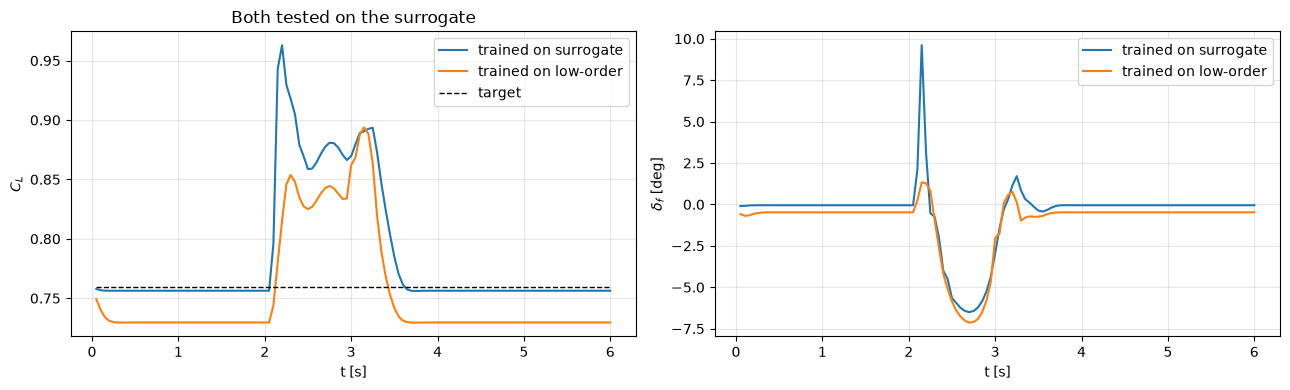

,agent,environment,mean_RMSE,max_abs_flap_deg,mean_abs_flap_deg,mean_CD,action_roughness
0,SAC trained on surrogate,tested on surrogate,0.05423,10.68000,1.02170,0.00979,0.02279
1,SAC trained on surrogate,tested on low-order,0.14417,12.05141,2.75528,0.02402,0.03327
2,SAC trained on low-order,tested on surrogate,0.06069,9.38689,1.10721,0.00959,0.01313
3,SAC trained on low-order,tested on low-order,0.05075,10.79008,0.92851,0.02022,0.02047
4,uncontrolled,tested on surrogate,0.14963,0.00000,0.00000,0.00989,0.00000
5,uncontrolled,tested on low-order,0.15109,0.00000,0.00000,0.02052,0.00000


In [31]:
class LowOrderAirfoilEnv(AirfoilSurrogateGymEnv):
    """Same environment, low-order steady aerodynamics (Section 19)."""

    def __init__(self, **kw):
        super().__init__(**kw)
        if kw.get("cl_target") is None:
            self.cl_target = float(low_order_lift(np.deg2rad(self.alpha0_deg)))
        self.reset()

    def _aero(self, gust_angle_deg):
        alpha_eq_deg = self._equivalent_alpha_deg(gust_angle_deg)
        cl_qs, cd = low_order_aero(alpha_eq_deg, self.cl, self.flap_deg)
        return cl_qs, cd, alpha_eq_deg

    def reset(self, seed=None, options=None):
        obs, info = super().reset(seed=seed, options=options)
        self.cl = float(low_order_lift(np.deg2rad(self.alpha0_deg)))
        self.cd = low_order_aero(self.alpha0_deg, self.cl, 0.0)[1]
        return self._get_obs(), info


check_env(LowOrderAirfoilEnv(), warn=True)
low_agent = train_agent(MODEL_NAME, f"ex2_{MODEL_NAME.lower()}_low_order_model", LowOrderAirfoilEnv(random_gust=True))
rows = []
for agent_label, agent in ((f"{MODEL_NAME} trained on surrogate", model), (f"{MODEL_NAME} trained on low-order", low_agent)):
    for env_label, env_cls in (("tested on surrogate", AirfoilSurrogateGymEnv), ("tested on low-order", LowOrderAirfoilEnv)):
        rows.append({"agent": agent_label, "environment": env_label, **suite_metrics(agent, agent_label, env_cls=env_cls)})
for env_label, env_cls in (("tested on surrogate", AirfoilSurrogateGymEnv), ("tested on low-order", LowOrderAirfoilEnv)):
    rows.append({"agent": "uncontrolled", "environment": env_label, **suite_metrics(zero_policy, "uncontrolled", env_cls=env_cls)})
ex2_table = pd.DataFrame(rows).drop(columns="configuration")
ex2_table.to_csv(EX_DIR / "ex2_model_fidelity.csv", index=False)
print("Targets: surrogate", round(AirfoilSurrogateGymEnv().cl_target, 4), "| low-order", round(LowOrderAirfoilEnv().cl_target, 4))

tr_s = fly(model, 2.5, 1.3); tr_l = fly(low_agent, 2.5, 1.3)
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(tr_s["time"], tr_s["cl"], label="trained on surrogate"); ax[0].plot(tr_l["time"], tr_l["cl"], label="trained on low-order")
ax[0].plot(tr_s["time"], tr_s["cl_target"], "k--", lw=1, label="target"); ax[0].set_ylabel(r"$C_L$"); ax[0].set_title("Both tested on the surrogate")
ax[1].plot(tr_s["time"], tr_s["flap_deg"], label="trained on surrogate"); ax[1].plot(tr_l["time"], tr_l["flap_deg"], label="trained on low-order")
ax[1].set_ylabel(r"$\delta_f$ [deg]")
for a in ax: a.set_xlabel("t [s]"); a.grid(True, alpha=0.3); a.legend()
fig.tight_layout(); fig.savefig(EX_DIR / "ex2_model_fidelity.png", dpi=120); plt.show()
ex2_table[["agent", "environment", "mean_RMSE", "max_abs_flap_deg", "mean_abs_flap_deg", "mean_CD", "action_roughness"]].round(5)

## Exercise 3 — Reynolds-number sensitivity *(executed)*

The main policy (trained at $Re=4\times10^6$) is evaluated at nine Reynolds numbers covering the database range $2$–$6\times10^6$. For each $Re$ the target is that $Re$'s own zero-gust equilibrium, as in Section 25.

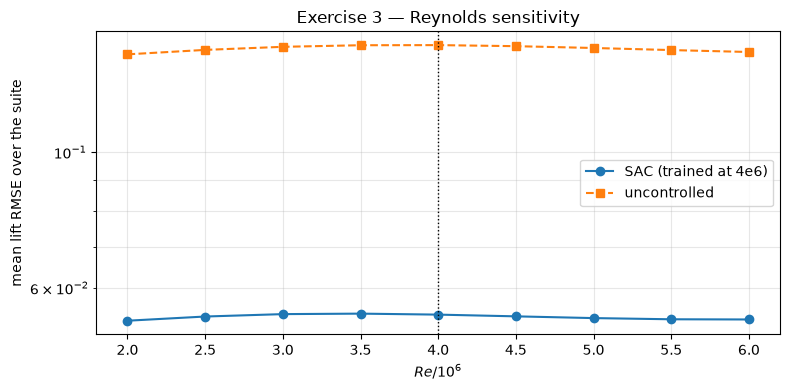

,Re,cl_target,mean_RMSE,uncontrolled_mean_RMSE,max_abs_flap_deg,mean_CD
0,2000000.0,0.76105,0.05300,0.14452,10.64651,0.01123
1,2500000.0,0.75853,0.05384,0.14696,10.67761,0.01074
2,3000000.0,0.75762,0.05433,0.14867,10.69278,0.01034
3,3500000.0,0.75816,0.05443,0.14956,10.69225,0.01002
4,4000000.0,0.75949,0.05423,0.14963,10.68000,0.00979
5,4500000.0,0.76073,0.05388,0.14903,10.66262,0.00962
6,5000000.0,0.76107,0.05353,0.14801,10.64735,0.00952
7,5500000.0,0.76006,0.05329,0.14686,10.63990,0.00946
8,6000000.0,0.75766,0.05325,0.14580,10.64295,0.00944


In [32]:
re_values = np.arange(2.0e6, 6.01e6, 0.5e6)
rows = []
for re_value in re_values:
    target = AirfoilSurrogateGymEnv(reynolds=re_value).cl_target
    rows.append({"Re": re_value, "cl_target": target, **suite_metrics(model, MODEL_NAME, reynolds=re_value),
                 "uncontrolled_mean_RMSE": suite_metrics(zero_policy, "unc", reynolds=re_value)["mean_RMSE"]})
ex3_table = pd.DataFrame(rows).drop(columns="configuration")
ex3_table.to_csv(EX_DIR / "ex3_reynolds_sensitivity.csv", index=False)
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(ex3_table.Re / 1e6, ex3_table.mean_RMSE, "o-", label=f"{MODEL_NAME} (trained at 4e6)")
ax.plot(ex3_table.Re / 1e6, ex3_table.uncontrolled_mean_RMSE, "s--", label="uncontrolled")
ax.axvline(4.0, color="k", ls=":", lw=1); ax.set_xlabel(r"$Re/10^6$"); ax.set_ylabel("mean lift RMSE over the suite")
ax.set_yscale("log"); ax.grid(True, which="both", alpha=0.3); ax.legend(); ax.set_title("Exercise 3 — Reynolds sensitivity")
fig.tight_layout(); fig.savefig(EX_DIR / "ex3_reynolds_sensitivity.png", dpi=120); plt.show()
ex3_table[["Re", "cl_target", "mean_RMSE", "uncontrolled_mean_RMSE", "max_abs_flap_deg", "mean_CD"]].round(5)

## Exercise 4 — Geometry sensitivity *(executed)*

The main policy (trained on the 2412-like section) is evaluated on eight NACA four-digit sections, all inside the parameter ranges of the CFD training data ($m\le7$, $p\le7$, $5\le t\le20$).

In [33]:
geometries = [("0012", 0, 0, 12), ("0018", 0, 0, 18), ("2412", 2, 4, 12), ("2418", 2, 4, 18),
              ("4412", 4, 4, 12), ("4415", 4, 4, 15), ("6409", 6, 4, 9), ("6412", 6, 4, 12)]
rows = []
for name, m_, p_, t_ in geometries:
    kw = dict(naca_m=float(m_), naca_p=float(p_), naca_t=float(t_))
    target = AirfoilSurrogateGymEnv(**kw).cl_target
    rows.append({"NACA": name, "cl_target": target, **suite_metrics(model, MODEL_NAME, **kw),
                 "uncontrolled_mean_RMSE": suite_metrics(zero_policy, "unc", **kw)["mean_RMSE"]})
ex4_table = pd.DataFrame(rows).drop(columns="configuration")
ex4_table.to_csv(EX_DIR / "ex4_geometry_sensitivity.csv", index=False)
ex4_table[["NACA", "cl_target", "mean_RMSE", "uncontrolled_mean_RMSE", "max_abs_flap_deg", "mean_CD", "fraction_outside_trusted"]].round(5)

,NACA,cl_target,mean_RMSE,uncontrolled_mean_RMSE,max_abs_flap_deg,mean_CD,fraction_outside_trusted
0,0012,0.50173,0.16529,0.14440,12.35348,0.01029,0.0
1,0018,0.48187,0.17408,0.13810,12.47966,0.01151,0.0
2,2412,0.75949,0.05423,0.14963,10.68000,0.00979,0.0
3,2418,0.70777,0.06320,0.13466,10.92704,0.01169,0.0
4,4412,0.97917,0.06307,0.13823,9.39611,0.01042,0.0
5,4415,0.92989,0.04617,0.12995,8.76533,0.01155,0.0
6,6409,1.19638,0.14885,0.13538,10.96276,0.01028,0.0
7,6412,1.16839,0.13381,0.12841,10.73322,0.01130,0.0


## Exercise 5 — Reward sensitivity *(executed)*

One weight is raised at a time (the others keep their defaults): `drag_weight` 0.02 → 1.0, `effort_weight` 0.015 → 0.2, `smoothness_weight` 0.02 → 0.3.

In [34]:
variants = {"drag_weight=1.0": dict(drag_weight=1.0), "effort_weight=0.2": dict(effort_weight=0.2),
            "smoothness_weight=0.3": dict(smoothness_weight=0.3)}
rows = [baseline_rows[1]]
for label, kw in variants.items():
    agent = train_agent(MODEL_NAME, f"ex5_{MODEL_NAME.lower()}_{label.replace('=', '_').replace('.', 'p')}",
                        AirfoilSurrogateGymEnv(random_gust=True, **kw))
    rows.append(suite_metrics(agent, f"{MODEL_NAME} with {label}"))
ex5_table = pd.DataFrame(rows)
ex5_table.to_csv(EX_DIR / "ex5_reward_sensitivity.csv", index=False)
ex5_table[["configuration", "mean_RMSE", "max_abs_flap_deg", "mean_abs_flap_deg", "mean_CD", "action_roughness"]].round(5)

loading ../models/04_airfoil_gust_control_cfd_surrogate/exercises/ex5_sac_drag_weight_1p0.zip
loading ../models/04_airfoil_gust_control_cfd_surrogate/exercises/ex5_sac_effort_weight_0p2.zip
loading ../models/04_airfoil_gust_control_cfd_surrogate/exercises/ex5_sac_smoothness_weight_0p3.zip


,configuration,mean_RMSE,max_abs_flap_deg,mean_abs_flap_deg,mean_CD,action_roughness
0,"SAC (main, Section 13)",0.05423,10.68000,1.02170,0.00979,0.02279
1,SAC with drag_weight=1.0,0.06425,12.50673,0.91278,0.00972,0.07602
2,SAC with effort_weight=0.2,0.14461,9.97760,0.84578,0.00970,0.02328
3,SAC with smoothness_weight=0.3,0.06849,11.65307,1.18958,0.00987,0.01884


## Exercise 6 — Domain protection *(executed)*

The trusted range is **derived from the training database** (minimum and maximum angle of the CFD training cases). The reward gets the extra term $-\lambda_{\mathrm{domain}}\left[\max(0,\alpha_{\mathrm{eq}}-\alpha_{\max})^2+\max(0,\alpha_{\min}-\alpha_{\mathrm{eq}})^2\right]$ with $\lambda_{\mathrm{domain}}=0.1\ \mathrm{deg^{-2}}$. To make the constraint matter, both agents compared here are trained with gusts up to $\pm6$ m/s (gust angles up to about $11^\circ$), and tested on gusts of $\pm5$ and $\pm6.5$ m/s.

In [35]:
class ProtectedAirfoilEnv(AirfoilSurrogateGymEnv):
    def __init__(self, domain_weight=0.1, alpha_range=(TRUST_LO, TRUST_HI), **kw):
        self.domain_weight, self.alpha_range = domain_weight, alpha_range
        super().__init__(**kw)

    def step(self, action):
        obs, reward, terminated, truncated, info = super().step(action)
        a, (lo, hi) = info["alpha_eq_deg"], self.alpha_range
        penalty = self.domain_weight * (max(0.0, a - hi)**2 + max(0.0, lo - a)**2)
        info["domain_penalty"] = penalty
        return obs, reward - penalty, terminated, truncated, info


wide = dict(random_gust=True, gust_amplitude_range=(-6.0, 6.0))
plain_wide = train_agent(MODEL_NAME, f"ex6_{MODEL_NAME.lower()}_wide_gusts_unprotected", AirfoilSurrogateGymEnv(**wide))
prot_wide = train_agent(MODEL_NAME, f"ex6_{MODEL_NAME.lower()}_wide_gusts_protected", ProtectedAirfoilEnv(**wide))
strong = [(5.0, 1.2), (-5.0, 1.2), (6.5, 1.0), (-6.5, 1.0)]
ex6_table = pd.DataFrame([
    suite_metrics(zero_policy, "uncontrolled", gusts=strong),
    suite_metrics(plain_wide, "wide-gust training, no protection", gusts=strong),
    suite_metrics(prot_wide, "wide-gust training, domain penalty", gusts=strong),
])
ex6_table.to_csv(EX_DIR / "ex6_domain_protection.csv", index=False)
ex6_table[["configuration", "mean_RMSE", "alpha_eq_min", "alpha_eq_max", "fraction_outside_trusted", "max_abs_flap_deg", "mean_CD"]].round(5)

loading ../models/04_airfoil_gust_control_cfd_surrogate/exercises/ex6_sac_wide_gusts_unprotected.zip
loading ../models/04_airfoil_gust_control_cfd_surrogate/exercises/ex6_sac_wide_gusts_protected.zip


,configuration,mean_RMSE,alpha_eq_min,alpha_eq_max,fraction_outside_trusted,max_abs_flap_deg,mean_CD
0,uncontrolled,0.26393,-7.22512,17.22512,0.02083,0.00000,0.01027
1,"wide-gust training, no protection",0.26115,-6.93311,19.85916,0.04583,14.32261,0.01059
2,"wide-gust training, domain penalty",0.21299,-4.15367,17.43223,0.00833,13.86960,0.01015


## Exercise 7 — Robust training with a randomised Reynolds number *(executed)*

`reset()` now draws $Re\sim\mathcal U(2,6)\times10^6$ at the start of every training episode, and sets the target to that $Re$'s zero-gust equilibrium. The observation is unchanged (it does not contain $Re$), so the agent must find one policy that works across the range. Both agents are evaluated over the Reynolds sweep of Exercise 3.

loading ../models/04_airfoil_gust_control_cfd_surrogate/exercises/ex7_sac_random_reynolds.zip


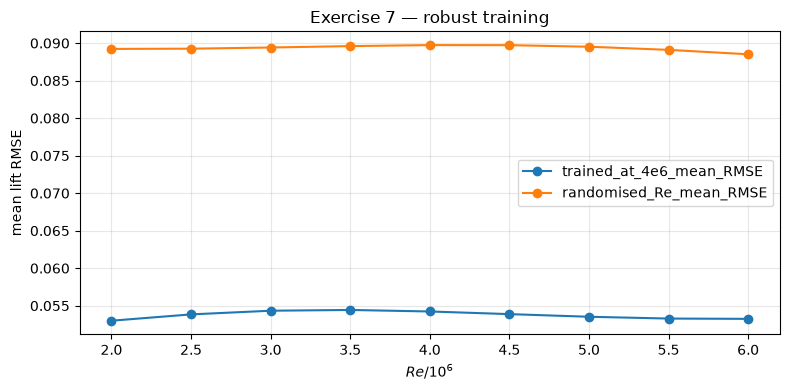

,Re,trained_at_4e6_mean_RMSE,randomised_Re_mean_RMSE
0,2000000.0,0.05300,0.08922
1,2500000.0,0.05384,0.08926
2,3000000.0,0.05433,0.08941
3,3500000.0,0.05443,0.08960
4,4000000.0,0.05423,0.08973
5,4500000.0,0.05388,0.08972
6,5000000.0,0.05353,0.08951
7,5500000.0,0.05329,0.08910
8,6000000.0,0.05325,0.08851


In [36]:
class RandomReynoldsEnv(AirfoilSurrogateGymEnv):
    def __init__(self, re_range=(2.0e6, 6.0e6), **kw):
        self.re_range = re_range
        super().__init__(**kw)

    def reset(self, seed=None, options=None):
        if seed is not None:
            gym.Env.reset(self, seed=seed)
        self.reynolds = float(self.np_random.uniform(*self.re_range))
        self.cl_target = predict_airfrans_aero(self.reynolds, self.alpha0_deg, self.naca_m, self.naca_p, self.naca_t)[0]
        return super().reset(seed=None, options=options)


check_env(RandomReynoldsEnv(), warn=True)
robust_agent = train_agent(MODEL_NAME, f"ex7_{MODEL_NAME.lower()}_random_reynolds", RandomReynoldsEnv(random_gust=True))
rows = []
for re_value in re_values:
    rows.append({"Re": re_value,
                 "trained_at_4e6_mean_RMSE": suite_metrics(model, "fixed", reynolds=re_value)["mean_RMSE"],
                 "randomised_Re_mean_RMSE": suite_metrics(robust_agent, "robust", reynolds=re_value)["mean_RMSE"]})
ex7_table = pd.DataFrame(rows)
ex7_table.to_csv(EX_DIR / "ex7_robust_reynolds.csv", index=False)
ax = ex7_table.set_index(ex7_table.Re / 1e6)[["trained_at_4e6_mean_RMSE", "randomised_Re_mean_RMSE"]].plot(marker="o", figsize=(8, 4))
ax.set_xlabel(r"$Re/10^6$"); ax.set_ylabel("mean lift RMSE"); ax.grid(True, alpha=0.3); ax.set_title("Exercise 7 — robust training")
plt.tight_layout(); plt.savefig(EX_DIR / "ex7_robust_reynolds.png", dpi=120); plt.show()
ex7_table.round(5)

In [37]:
# ================================================================
# INDEX OF SAVED OUTPUTS
# ================================================================
for p in sorted(EX_DIR.iterdir()):
    print(p)
for p in sorted(Path("../models/04_airfoil_gust_control_cfd_surrogate").rglob("*.zip")):
    print(p)

../results/04_airfoil_gust_control_cfd_surrogate/ex1_algorithm_comparison.csv
../results/04_airfoil_gust_control_cfd_surrogate/ex2_model_fidelity.csv
../results/04_airfoil_gust_control_cfd_surrogate/ex2_model_fidelity.png
../results/04_airfoil_gust_control_cfd_surrogate/ex3_reynolds_sensitivity.csv
../results/04_airfoil_gust_control_cfd_surrogate/ex3_reynolds_sensitivity.png
../results/04_airfoil_gust_control_cfd_surrogate/ex4_geometry_sensitivity.csv
../results/04_airfoil_gust_control_cfd_surrogate/ex5_reward_sensitivity.csv
../results/04_airfoil_gust_control_cfd_surrogate/ex6_domain_protection.csv
../results/04_airfoil_gust_control_cfd_surrogate/ex7_robust_reynolds.csv
../results/04_airfoil_gust_control_cfd_surrogate/ex7_robust_reynolds.png
../models/04_airfoil_gust_control_cfd_surrogate/airfoil_surrogate_sac_final.zip
../models/04_airfoil_gust_control_cfd_surrogate/exercises/ex1_ppo.zip
../models/04_airfoil_gust_control_cfd_surrogate/exercises/ex1_td3.zip
../models/04_airfoil_gust_c

## 30. What would make this model more physical?

Several extensions are possible.

### A flap-dependent CFD surrogate

Generate CFD data with flap deflection as an additional input:

$$
(Re,\alpha,m,p,t,\delta_f)
\rightarrow
(C_L,C_D).
$$

This would remove the equivalent-angle approximation.

### An unsteady aerodynamic surrogate

Include state history or temporal variables so that the model learns effects such as dynamic lag or hysteresis.

### Higher-fidelity validation

A controller learned with the surrogate should ultimately be tested against a model that was **not used during training**, for example:

- an unsteady CFD solver,
- higher-fidelity reduced-order data,
- experimental measurements.

This separates **training efficiency** from **physical validation**.

## 31. Main message

The important progression across Stages 2–4 is

$$
\boxed{
\text{DRL with simple physics}
\rightarrow
\text{CFD surrogate}
\rightarrow
\text{DRL with CFD-informed physics}
}
$$

The reinforcement-learning algorithm did not fundamentally change.

What changed was the environment.

That distinction is essential:

$$
\boxed{
\text{A DRL controller can only be as trustworthy as the environment used to train and validate it.}
}
$$

The AirfRANS surrogate makes the aerodynamic model richer while keeping the computational cost low enough for repeated DRL interaction. At the same time, the exercise exposes new questions about surrogate validity, extrapolation, missing unsteady physics, and generalization.

These questions motivate the next step:

$$
\boxed{
\text{robust CFD-informed DRL through domain randomization}
}
$$

# Appendix — written answers and findings

These cells are appended at the end so that the numbering of all executed cells is unchanged.

## Animation analysis — answers

This run uses the **provided** surrogate files (`airfrans_cl_cd_surrogate.keras`, `airfrans_cl_cd_scalers.joblib`); their test accuracy is measured in Stage 3, cell 90 ($C_L$ RMSE 0.0259, $R^2$ 0.998; $C_D$ RMSE 0.00087, $R^2$ 0.972).

- **A1** — The SAC policy beats the uncontrolled RMSE (0.1354) at the first snapshot (step 1,000) and is within 10 % of its final RMSE (0.0599) by step 3,000. Its best snapshot was also at step 3,000 (0.0289); later training did not keep that level.
- **A2** — The flap reacts at the gust onset ($t=2.10$ s), before the uncontrolled lift error exceeds 0.01 ($t=2.15$ s) — but its **first move is in the wrong direction**: the flap rises to +9.61° at $t=2.15$ s, lifting $C_L$ to 0.962 at $t=2.20$ s, before reversing to −6.46° at $t=2.70$ s (visible in the dashboard animation). The same transient appeared in the earlier run with the retrained surrogate, so it is a property of this SAC training run rather than of one surrogate.
- **A3** — At the gust peak the flap has moved −6.38° against a +4.76° gust angle, a ratio of −1.34, i.e. about 74 % of the −1.82 needed to cancel the angle.


## Summary of the executed exercises

| # | Finding (one seed per configuration; mean lift RMSE over the 5-gust suite, uncontrolled 0.150) |
|---|---|
| 1 | PPO 0.0098 and TD3 0.0188 vs SAC (main) 0.0542 — at this budget the SAC run is the weakest. |
| 2 | Surrogate-trained SAC: 0.054 on its own model, 0.144 on the low-order model (≈ uncontrolled). Low-order-trained SAC: 0.051 on its own model, 0.061 on the surrogate. Targets differ (0.7595 vs 0.5483). Single SAC seeds: differences of this size are within training variance. |
| 3 | Over $Re = 2$–$6\times10^6$ the error barely changes (0.053–0.054): the surrogate's response to $Re$ is mild in this range. |
| 4 | 2412/2418/4412/4415 sections: 0.046–0.063; symmetric 0012/0018: 0.165/0.174 and 6409/6412: 0.149/0.134 — worse than uncontrolled for those four. |
| 5 | effort_weight 0.2 made the controller timid (0.145); drag_weight 1.0 and smoothness_weight 0.3 gave 0.064 and 0.068. |
| 6 | With wide-gust training, the domain penalty kept $\alpha_{eq}$ within −4.2…17.4° (vs up to 19.9° without) and cut the time outside the trusted range from 4.6 % to 0.8 %, with a lower error (0.213 vs 0.261). |
| 7 | Randomising $Re$ during training gave a *higher* error across the sweep (0.089 vs 0.053–0.054) — the opposite of the earlier run with the retrained surrogate; with one seed, neither direction is conclusive. |
